<div style="background:linear-gradient(120deg,#12372A,#436850);padding:28px;border-radius:18px;color:#fff">
  <div style="font-size:14px;letter-spacing:2px;opacity:.85">ЕДИНЫЙ ПРОЕКТ · БИЗНЕС.РУ · ТОЛЬКО РОЗНИЦА</div>
  <h1 style="color:white;margin:8px 0">🌷 Аналитика цветочного магазина</h1>
  <p style="font-size:17px;margin:0">Продажи · маржа · ассортимент · остатки · списания · закупки · контроль потерь</p>
  <p style="opacity:.85;margin-top:14px">Для новичка: понятные объяснения, проверки данных, графики и итоговый Excel-отчёт.</p>
</div>

## Что делает этот блокнот

Это единый ноутбук вместо нескольких разрозненных версий. Он рассчитан на розничную точку цветочного магазина. Основной источник — выгрузки из **Бизнес.Ру**, в том числе старый Excel-формат `.xls`.

- объясняет, какие отчёты выгружать и зачем;
- автоматически ищет файлы в папке `data/`;
- разбирает отчёт **«Движение товаров»** и, если доступно, **«Продажи»**;
- показывает выручку и маржу, ABC/XYZ, динамику, товары без движения, ориентир закупки;
- ищет необычные списания, возвраты, цены и ошибки складского учёта;
- сохраняет итоговые таблицы в `output/Отчет_розница_цветы.xlsx`.

> **Важное ограничение:** в сообщении не было реального файла `Движение товаров.xls`, поэтому автоматический разбор именно вашей выгрузки нельзя подтвердить на реальных данных. Если папка `data/` пустая, блокнот запускает демонстрационный пример, чтобы вы могли увидеть результат. Когда положите настоящий файл, он переключится на реальные данные. Если формат отчёта в вашем аккаунте отличается, ноутбук покажет понятную диагностику, а не будет молча выдавать случайные цифры.

## Содержание

1. [Быстрый запуск](#quickstart)
2. [Где брать данные в Бизнес.Ру](#businessru)
3. [Контроль потерь и хищений](#loss-control)
4. Настройки и загрузка файлов
5. Проверка качества данных
6. KPI и динамика продаж
7. Ассортимент: ABC/XYZ и категории
8. Чеки и товары в одной покупке
9. Цены, маржа, остатки и закупки
10. Сигналы для проверки
11. Прогноз и итоговый отчёт

<a id="quickstart"></a>
# 1. Быстрый запуск для новичка

### Шаг 1. Подготовьте папку проекта

Рядом с ноутбуком создайте папку `data`. Положите туда выгрузки из Бизнес.Ру. Пример:

```text
flower_analysis/
├── Анализ_розницы.ipynb
├── data/
│   ├── 01_Движение_товаров.xls
│   ├── 02_Продажи.xlsx
│   ├── 03_Списания.xlsx
│   ├── 04_Остатки.xlsx
│   ├── 05_Инвентаризация.xlsx
│   └── 06_Кассовые_чеки.xlsx
└── output/             ← появится автоматически
```

Названия файлов можно менять: поиск работает по ключевым словам. Если внутри `data/` есть несколько похожих выгрузок, задайте точные имена в ячейке «Настройки».

### Шаг 2. Установите библиотеки

Откройте командную строку в папке проекта и выполните:

```bash
python -m pip install --upgrade pandas numpy matplotlib openpyxl xlrd jupyterlab
```

- `pandas` и `numpy` — обработка таблиц и расчёты;
- `matplotlib` — графики;
- `openpyxl` — чтение/запись `.xlsx` и оформление итогового отчёта;
- `xlrd` — чтение старых файлов `.xls`;
- `jupyterlab` — среда, в которой выполняется блокнот.

Если используете Anaconda, можно установить эти пакеты через Anaconda Prompt.

### Шаг 3. Запустите весь блокнот

```bash
jupyter lab
```

Откройте этот `.ipynb` и выберите **Run → Run All Cells**. Сначала выполните ячейки сверху вниз, не перескакивая через разделы: нижние разделы используют результаты верхних.

### Шаг 4. Проверьте подписи к данным

Если видите «демонстрационные данные», отчёт показывает пример, а не реальные показатели магазина. Если увидите «данные из Бизнес.Ру», проверьте число строк, даты и первые записи — это самый важный контроль перед интерпретацией результатов.

### Что означают пометки

- **Факт из выгрузки** — сумма/количество содержались в загруженном отчёте.
- **Оценка** — сумма рассчитана по средней цене товара или заданной наценке; это не замена фискальному отчёту.
- **Сигнал для проверки** — необычное событие, которое надо сверить с документами. Это не доказательство кражи.

<a id="businessru"></a>
# 2. Где брать данные именно в Бизнес.Ру

Ссылка [https://w746008.business.ru/supply](https://w746008.business.ru/supply) ведёт в раздел снабжения/закупок. Это полезно для заказов и закупок, но не следует считать, что именно на этой странице находится вся аналитика. Войдите в свой аккаунт Бизнес.Ру и найдите в основном меню раздел **«Отчёты»**, **«Аналитика»** или соответствующий отчёт в модуле склада/продаж. Точные пункты и доступность зависят от настроек аккаунта и прав пользователя.

В официальном описании Бизнес.Ру перечислены отчёты по анализу продаж, рентабельности, прибыли/убыткам, остаткам и движению товаров. В «Анализе продаж» доступны разрезы по сотрудникам и документам; в «Движении товаров» — движения, возвраты и внутренние перемещения; в «Остатках товаров» — остатки по складам/точкам. См. [официальное описание отчётов Бизнес.Ру](https://online.business.ru/vozmozhnosti/otchety-i-analitika-prodazh/).

## Какие таблицы нужны

| Приоритет | Что найти в Бизнес.Ру | Что должно быть в выгрузке | Для чего нужно |
|---|---|---|---|
| **Обязательно** | **Склад → Движение товаров** | Товар, начальный остаток, приход/расход в штуках, стоимость движений, конечный остаток, документ, дата | Остатки, себестоимость движений, списания, возвраты, поиск несоответствий |
| **Обязательно** | **Продажи / Анализ продаж** | Товар, количество, сумма/выручка, цена, желательно себестоимость и скидка | Фактическая выручка по товарам, маржа, ABC-анализ |
| Очень желательно | **Кассовые чеки / товарные позиции чеков / отчёт по кассирам или сменам** | Номер чека, дата и время, товар, количество, сумма позиции, скидка/возврат; кассир, если поле доступно | Точный средний чек, почасовой анализ, корзина покупок и сравнение операций |
| Очень желательно | **Списания** | Дата, товар, количество, стоимость, причина, автор/владелец документа (если есть) | Анализ порчи и нестандартных списаний |
| Очень желательно | **Инвентаризация** | Учётный остаток, фактическое количество, разница | Главная проверка физической недостачи |
| Полезно | **Остатки товаров** | Товар, склад/розничная точка, остаток на выбранную дату, стоимость | Снимок склада, сверка с движением |
| Полезно | **Поступления** | Дата, товар, количество, закупочная цена, поставщик | Изменения закупочных цен и контроль поставщиков |

### Как выгружать — общий пошаговый принцип

1. Откройте нужный отчёт по названию. Не делайте скриншот: нужна именно таблица.
2. Выберите **одинаковую розничную точку/склад** во всех отчётах. Не смешивайте оптовый склад с розничным магазином.
3. Для отчётов за период задайте одинаковые даты начала и окончания. Для отчёта «Остатки товаров» выберите дату, на которую проверяете склад.
4. Включите максимально подробную детализацию и нужные колонки: товар, количество, цена/сумма, документ, дата, склад, скидка, возврат, сотрудник — если они доступны.
5. Выгрузите в Excel. Файл `.xls` подходит; переименовывать его в `.xlsx` простым изменением расширения нельзя.
6. Положите файл в `data/`. Перед запуском откройте его в Excel и проверьте, что там таблица, а не HTML-страница или картинка.

### Какой отчёт важнее всего

**«Движение товаров» — лучший старт, но его одного недостаточно для точного анализа продаж.** Отчёт движения полезен для количественного складского учёта и себестоимости движений. Для фактической суммы продажи после скидки, номера чека и кассира лучше использовать подробный отчёт по продажам/кассовым чекам. Если есть только сводка продаж по товару, анализ выручки по товарам возможен, но разрез по часам, чекам и сотрудникам может быть недоступен.

### Если не видите нужный отчёт

Попросите администратора Бизнес.Ру дать права на отчёты склада, продажи, чеки, списания и инвентаризацию. Если названия отличаются, ориентируйтесь на набор столбцов из таблицы выше; можно обратиться в поддержку Бизнес.Ру. Меню в вашей версии аккаунта может отличаться от публичных описаний.

<a id="loss-control"></a>
# 3. Как контролировать потери в цветочном магазине

У цветов естественные потери выше, чем у товаров длительного хранения: срезка вянет, товар списывается, букеты собираются из нескольких позиций. Поэтому сравнивать нужно не только выручку, но и **движения, списания, возвраты, скидки и результаты фактической инвентаризации**.

| Риск-сценарий | Что можно увидеть в данных | Чем подтвердить | Полезный контроль |
|---|---|---|---|
| Продажа не отражена в кассе | Учетный расход есть, а чек/выручка не сходятся | Фискальные чеки, кассовая смена, документы движения | Ежедневно сверять чековую выручку, кассу и расход товара |
| Необоснованный возврат или отмена | Возвраты/отмены необычно часты или сосредоточены в отдельных сменах | Исходный чек, причина возврата, подтверждение возврата денег | Возврат с причиной и подтверждением ответственного |
| Скидки или ручное изменение цены | Фактическая цена заметно ниже обычной цены товара | Прайс, история скидок, карта лояльности, согласование | Лимиты скидок и отдельное согласование больших скидок |
| Списание под видом порчи | Резкий всплеск списаний, повторяющиеся причины или товары | Фото/акт порчи, количество, партия и сроки хранения | Вести причину списания и подтверждать крупные списания двумя людьми |
| Физическая недостача | Фактический остаток ниже учётного | Независимая инвентаризация, движения и документы | Частые выборочные пересчёты топовых и дорогих позиций |
| Пересортица | Плюс по одному похожему SKU и минус по другому | Штрихкод/сорт/длина/цвет, накладные и пересчёт | Унифицировать карточки товара и единицы измерения |
| Неправильное списание материалов в букеты | Упаковка/зелень уходит быстрее, чем ожидается | Нормы рецептур и фактический состав букетов | Завести техкарты или нормы расхода для типовых букетов |
| Необычная закупочная цена | Цена поставки сильно отличается от обычной | Счёт, накладная, прайс поставщика | Сверять цену по SKU и поставщику до закрытия периода |

## Что важно не перепутать

- Сигнал программы **не означает**, что конкретный человек что-то украл. Причиной могут быть ошибка кассира, пересорт, неверная единица измерения, задержка оформления, возврат, акция, праздничная смена или порча.
- Отчёт «Движение товаров» обычно не доказывает физическую недостачу сам по себе: учётный остаток рассчитывается по документам. Для фактической недостачи нужна инвентаризация.
- Не приписывайте документ сотруднику по косвенному признаку. «Владелец документа» может быть тем, кто оформил документ, а не тот, кто работал на смене.
- Не составляйте рейтинг «кто ворует» по голым числам. Сначала сравните одинаковые роли, часы, количество смен, поток покупателей и ассортимент; затем проверьте документы и объяснения.

### Минимальный профилактический регламент

1. Каждый день: сверить кассовый итог, возвраты/отмены и списания.
2. Каждую неделю: вслепую пересчитать несколько дорогих/ходовых SKU и сравнить с учётом.
3. При списании: записать причину, количество, стоимость и ответственного; для крупных списаний — фото и второе подтверждение.
4. При возврате: сохранять связь с исходным чеком и причину.
5. Ежемесячно: сравнить динамику списаний, скидок, возвратов, маржи и закупочных цен; каждое крупное отклонение подтвердить документами.

# 4. Настройки — обычно достаточно проверить только эту ячейку

Сначала ничего не меняйте. Если в папке `data/` по одному файлу каждого типа, блокнот попробует определить их автоматически. Если у вас несколько похожих выгрузок, впишите имя конкретного файла, например `01_Движение_товаров.xls`.

In [1]:
from pathlib import Path

# Папка с выгрузками относительно текущей папки запуска Jupyter.
DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")

# Оставьте None для автоматического поиска. Или задайте точное имя файла из папки data/.
MOVEMENT_FILE = None       # например: "01_Движение_товаров.xls"
SALES_FILE = None          # например: "02_Продажи.xlsx"
CHECKS_FILE = None         # подробные позиции чеков, если есть отдельная выгрузка
WRITEOFF_FILE = None       # подробные списания (причина/автор), если есть
STOCK_FILE = None          # отдельный отчёт «Остатки товаров», если есть
INVENTORY_FILE = None      # отчёт/документ инвентаризации, если есть

# Если не найден «Движение товаров», показать демонстрационный пример.
# Установите False, если хотите, чтобы без реального файла блокнот сразу останавливался.
USE_DEMO_IF_NO_MOVEMENT = True

# Период анализа. None = использовать все доступные даты из данных.
DATE_FROM = None           # пример: "2026-01-01"
DATE_TO = None             # пример: "2026-03-31"

# Базовые параметры анализа
TOP_N = 15                 # число товаров в топ-таблицах
SLOW_DAYS = 21             # нет продаж столько дней -> проверить товар на залеживание
COVER_DAYS = 4             # ориентир запаса в днях для скоропортящихся цветов
COVER_LOOKBACK = 28        # сколько последних дней использовать для скорости продаж
GLOBAL_MARKUP = 2.0        # резервная наценка к себестоимости, ТОЛЬКО если цены нет
MARGIN_TARGET = 40         # целевая валовая маржа, % (ориентир, не отраслевой стандарт)
PRICE_ALERT_PCT = 15       # сигнал, если цена сильно ниже медианной цены того же товара
MIN_PAIR_COUNT = 3         # минимальное число чеков для вывода пары товаров
FORECAST_DAYS = 14         # горизонт простого прогноза

# Столбцы отчёта «Движение товаров» Бизнес.Ру в типичной выгрузке.
# Это номера колонок с нуля. Обычно менять не нужно.
MOVEMENT_COLS = {
    "товар": 0,
    "склад": 1,
    "документ": 2,
    "начальный_остаток": 4,
    "приход_шт": 7,
    "приход_руб": 9,
    "расход_шт": 10,
    "расход_себест_руб": 12,
    "конечный_остаток": 13,
    "остаток_руб": 15,
}

print("✅ Настройки загружены")
print("📂 Рабочая папка:", Path.cwd())
print("📁 Папка данных:", DATA_DIR.resolve())

✅ Настройки загружены
📂 Рабочая папка: d:\Down\21school\muzflowers_analysis
📁 Папка данных: D:\Down\21school\muzflowers_analysis\data


# 5. Библиотеки и функции-помощники

Эта ячейка содержит повторно используемые функции: чтение `.xls/.xlsx/.csv`, распознавание чисел с запятой, поиск колонок и форматирование. Если код ниже вызывает ошибку, сначала проверьте, что выполнили все ячейки выше.

In [2]:
import re
import math
import warnings
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)

# Оформление графиков — спокойная цветовая палитра и читаемые подписи.
PALETTE = ["#246B54", "#E0A458", "#3D6D9A", "#B84A62", "#7B61A8", "#4D9B9B"]
ABC_COLORS = {"A": "#246B54", "B": "#E0A458", "C": "#B84A62"}
DAYS_RU = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
plt.rcParams.update({
    "figure.figsize": (12, 5), "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .22, "font.size": 10,
    "axes.titleweight": "bold", "figure.autolayout": False,
})

def norm_text(value):
    """Нормализует русское название: нижний регистр, ё -> е, лишние пробелы."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return ""
    text = str(value).replace("\xa0", " ").replace("ё", "е").lower()
    return re.sub(r"\s+", " ", text).strip()

def parse_number(value):
    """Преобразует '1 234,50 ₽', '(120,00)' и похожие значения в число."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return np.nan
    if isinstance(value, (int, float, np.integer, np.floating)):
        return float(value)
    s = str(value).strip().replace("\xa0", "").replace(" ", "")
    if s.lower() in {"", "nan", "none", "-", "—", "нет"}:
        return np.nan
    negative = s.startswith("(") and s.endswith(")")
    s = s.strip("()")
    s = re.sub(r"[^0-9,\.\-+]", "", s)
    if not s or s in {"-", "+", ".", ","}:
        return np.nan
    if "," in s and "." in s:
        # Если запятая правее точки, предполагаем русскую запись: 1.234,56.
        if s.rfind(",") > s.rfind("."):
            s = s.replace(".", "").replace(",", ".")
        else:
            # Англоязычная запись 1,234.56
            s = s.replace(",", "")
    elif "," in s:
        s = s.replace(",", ".")
    elif s.count(".") > 1:
        parts = s.split(".")
        if len(parts[-1]) in (1, 2):
            s = "".join(parts[:-1]) + "." + parts[-1]
        else:
            s = "".join(parts)
    elif "." in s and len(s.split(".")[-1]) == 3:
        # Запись вида 1.234 в русском отчёте чаще является разделителем тысяч.
        s = s.replace(".", "")
    try:
        result = float(s)
        return -abs(result) if negative else result
    except ValueError:
        return np.nan

def to_num(series):
    return series.map(parse_number)

def money(value):
    if pd.isna(value):
        return "—"
    return f"{value:,.0f} ₽".replace(",", " ")

def number_fmt(value):
    if pd.isna(value):
        return "—"
    return f"{value:,.1f}".replace(",", " ").replace(".0", "")

def percent(value):
    return "—" if pd.isna(value) else f"{value:.1f}%"

def rub_axis(x, pos=None):
    if abs(x) >= 1_000_000:
        return f"{x / 1_000_000:.1f} млн"
    if abs(x) >= 1_000:
        return f"{x / 1_000:.0f} тыс."
    return f"{x:.0f}"

def clean_item(value):
    """Удаляет типичные единицы измерения в конце наименования товара."""
    s = str(value).strip()
    s = re.sub(r",\s*(шт|кг|г|л|м|уп|компл|пара|рул|см)\.?\s*$", "", s, flags=re.I)
    return re.sub(r"\s+", " ", s).strip()

CATEGORY_RULES = [
    ("Розы", r"\bроз[аы]\b|кустов(ая|ые)? роз"),
    ("Хризантемы", r"хризантем"),
    ("Тюльпаны", r"тюльпан"),
    ("Пионы", r"пион"),
    ("Зелень и наполнители", r"эвкалипт|рускус|папоротник|аспидистр|салал|гипсофил|лимониум|зелень"),
    ("Горшечные растения", r"фаленопсис|орхиде|антуриум|спатифиллум|горшечн|шефлер|суккулент|кактус"),
    ("Упаковка и аксессуары", r"короб|открытк|пакет|кашпо|оазис|грунт|лента|ваза|топпер|крафт|пленк|плёнк|сетка|бумаг|упаков"),
    ("Услуги", r"услуг|доставк|сборк|оформлен|работа флорист"),
]
def categorize(item):
    text = norm_text(item)
    for category, pattern in CATEGORY_RULES:
        if re.search(pattern, text):
            return category
    return "Прочая срезка"

def safe_divide(a, b):
    return np.where(np.asarray(b) != 0, np.asarray(a) / np.asarray(b), np.nan)

print("✅ Библиотеки подключены, функции готовы")

✅ Библиотеки подключены, функции готовы


# 6. Поиск файлов и чтение Excel/CSV

Блокнот поддерживает `.xls`, `.xlsx` и `.csv`. В старом `.xls` библиотека `xlrd` обязательна. В этой ячейке блокнот также покажет список файлов, которые нашёл в `data/`.

In [3]:
SUPPORTED_EXTENSIONS = {".xls", ".xlsx", ".xlsm", ".csv"}

def list_data_files():
    if not DATA_DIR.exists():
        return []
    return sorted([p for p in DATA_DIR.iterdir()
                   if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
                   and not p.name.startswith("~$")])

def choose_file(manual_name, keywords, role):
    """Берёт явно указанный файл или ищет подходящий по имени. Не скрывает неоднозначность."""
    files = list_data_files()
    if manual_name:
        path = Path(manual_name)
        if not path.is_absolute():
            path = DATA_DIR / path
        if not path.exists():
            raise FileNotFoundError(f"Для роли «{role}» указан файл, но он не найден: {path}")
        return path
    terms = [norm_text(k) for k in keywords]
    matches = [p for p in files if all(t in norm_text(p.name) for t in terms)]
    if not matches:
        return None
    # Предпочитаем наиболее конкретное имя; при равенстве берём самый новый файл.
    matches.sort(key=lambda p: (sum(t in norm_text(p.name) for t in terms), p.stat().st_mtime), reverse=True)
    if len(matches) > 1:
        best_score = sum(t in norm_text(matches[0].name) for t in terms)
        tied = [p for p in matches if sum(t in norm_text(p.name) for t in terms) == best_score]
        if len(tied) > 1:
            print(f"⚠️ Для раздела «{role}» найдено несколько кандидатов. Выбран: {matches[0].name}")
            print("   Другие файлы:", ", ".join(p.name for p in tied[1:]))
            print("   Если выбран не тот период, укажите имя нужного файла в ячейке настроек.")
    return matches[0]

def read_raw_file(path):
    """Читает таблицу без предположения, что первая строка — заголовок."""
    path = Path(path)
    suffix = path.suffix.lower()
    if suffix in {".xls", ".xlsx", ".xlsm"}:
        try:
            engine = "xlrd" if suffix == ".xls" else "openpyxl"
            return pd.read_excel(path, header=None, dtype=object, engine=engine)
        except ImportError as exc:
            if suffix == ".xls":
                raise ImportError("Для чтения старого .xls установите xlrd: python -m pip install xlrd") from exc
            raise
    if suffix == ".csv":
        last_error = None
        for encoding in ("utf-8-sig", "cp1251", "utf-8"):
            for sep in (";", ",", "\t"):
                try:
                    df = pd.read_csv(path, header=None, dtype=object, encoding=encoding, sep=sep)
                    # Не принимаем разделитель, который дал одну колонку, если файл похож на CSV с разделителями.
                    if df.shape[1] > 1 or sep == "\t":
                        return df
                except Exception as exc:
                    last_error = exc
        raise ValueError(f"Не удалось прочитать CSV {path}: {last_error}")
    raise ValueError(f"Формат {suffix} не поддерживается. Используйте XLS, XLSX или CSV.")

def header_score(row):
    text = " | ".join(norm_text(x) for x in row if pd.notna(x))
    has_item = any(word in text for word in ("товар", "наименован", "номенклатур", "позици"))
    has_qty_or_money = any(word in text for word in ("кол", "колич", "сумм", "выруч", "цен", "себестоим"))
    return int(has_item) * 2 + int(has_qty_or_money)

def find_header_row(raw, search_rows=20):
    if raw.empty:
        return None
    limit = min(search_rows, len(raw))
    scores = [(header_score(raw.iloc[i].tolist()), i) for i in range(limit)]
    scores.sort(reverse=True)
    return scores[0][1] if scores and scores[0][0] >= 3 else None

def table_with_detected_header(raw, search_rows=20):
    """Находит строку с названиями колонок и возвращает таблицу с заголовками."""
    raw = raw.dropna(how="all").dropna(axis=1, how="all").reset_index(drop=True)
    header_row = find_header_row(raw, search_rows=search_rows)
    if header_row is None:
        return None, None
    headers = []
    used = Counter()
    for i, val in enumerate(raw.iloc[header_row].tolist()):
        name = str(val).strip() if pd.notna(val) else f"столбец_{i}"
        if not name or name.lower() == "nan":
            name = f"столбец_{i}"
        used[name] += 1
        if used[name] > 1:
            name = f"{name}_{used[name]}"
        headers.append(name)
    df = raw.iloc[header_row + 1:].copy()
    df.columns = headers
    df = df.dropna(how="all").reset_index(drop=True)
    return df, header_row

files_found = list_data_files()
if files_found:
    print("📂 Найдены файлы в data/:")
    display(pd.DataFrame({"Файл": [p.name for p in files_found],
                          "Формат": [p.suffix.lower() for p in files_found],
                          "Размер, КБ": [round(p.stat().st_size / 1024, 1) for p in files_found]}))
else:
    print("ℹ️ В data/ пока не найдено XLS/XLSX/CSV. Если нет «Движения товаров», ниже включится демо-пример.")

📂 Найдены файлы в data/:


,Файл,Формат,"Размер, КБ"
0,Движение товаров.xls,.xls,226.0
1,Инвентаризации.csv,.csv,8.4
2,Курская_Контроль_Октябрь.xlsx,.xlsx,46.9
3,Оприходования товаров.csv,.csv,13.6
4,Остатки товаров.csv,.csv,26.4
5,Поступления.csv,.csv,32.9
6,Продажи.csv,.csv,6.2
7,Списания товаров.csv,.csv,28.3


# 7. Разбираем «Движение товаров»

В типичной выгрузке «Движение товаров» несколько строк относятся к одному товару: строка с итогами, строка склада и ниже строки документов. Поэтому это не всегда обычная прямоугольная таблица с одной шапкой. Код ниже сохраняет логику такого отчёта и дополнительно проверяет, получилось ли распознать товары и документы.

Если ваша версия отчёта имеет другую структуру, прежде чем исправлять код, посмотрите первые строки исходной таблицы и номера колонок в настройке `MOVEMENT_COLS`. Нельзя просто переименовать `.xls` в `.xlsx`: формат файла от этого не меняется.

In [4]:
DOC_DATE_RE = re.compile(r"(?P<date>\d{2}[.\-/]\d{2}[.\-/]\d{4})(?:\s+(?P<time>\d{1,2}:\d{2}(?::\d{2})?))?")
DOC_NO_RE = re.compile(r"№\s*(?P<number>.*?)\s+от\s+\d{2}[.\-/]\d{2}[.\-/]\d{4}", re.I)

def parse_document_title(value):
    """Из названия документа извлекает тип, номер, дату и час, если они есть."""
    raw = str(value).replace("\xa0", " ").strip()
    date_match = DOC_DATE_RE.search(raw)
    date = pd.NaT
    hour = np.nan
    if date_match:
        date = pd.to_datetime(date_match.group("date"), dayfirst=True, errors="coerce")
        time_text = date_match.group("time")
        if time_text:
            try:
                hour = int(time_text.split(":")[0])
            except Exception:
                pass
    no_match = DOC_NO_RE.search(raw)
    number = no_match.group("number").strip() if no_match else ""
    if "№" in raw:
        doc_type = raw.split("№", 1)[0].strip()
    elif date_match:
        doc_type = raw[:date_match.start()].strip()
    else:
        doc_type = raw[:60]
    return doc_type or "Тип не распознан", number, date, hour

def parse_movement_report(path):
    """Возвращает два датафрейма: складские итоги по товарам и строки документов."""
    raw = read_raw_file(path).dropna(axis=1, how="all").reset_index(drop=True)
    if raw.shape[1] < 10:
        raise ValueError(
            f"В «Движении товаров» только {raw.shape[1]} колонок. Ожидается типичная широкая выгрузка Бизнес.Ру. "
            "Откройте файл в Excel и проверьте, что это именно отчёт «Движение товаров», выгруженный в Excel."
        )
    # В типичном отчёте таблица начинается через одну строку после строки заголовка «Наименование».
    header_candidates = [i for i in range(min(30, len(raw)))
                         if raw.iloc[i].astype(str).str.contains("наименован", case=False, na=False).any()]
    if header_candidates:
        start = header_candidates[0] + 2
    else:
        # Если заголовок отчёта изменён, пробуем найти первую строку, похожую на товарную.
        candidate = None
        for i in range(min(30, len(raw))):
            if pd.notna(raw.iat[i, 0]) and any(pd.notna(raw.iat[i, j]) for j in [4, 7, 9, 10, 12] if j < raw.shape[1]):
                candidate = i
                break
        start = candidate if candidate is not None else 0
    data = raw.iloc[start:].copy().reset_index(drop=True)
    # Обеспечиваем наличие всех столбцов, которые используются типовой выгрузкой.
    needed = max(max(MOVEMENT_COLS.values()) + 1, data.shape[1])
    data = data.reindex(columns=range(needed))

    item_text = data[MOVEMENT_COLS["товар"]].astype(str).str.strip()
    invalid_text = item_text.str.lower().str.contains(r"наименован|^итого$|^всего$|^товар$|^nan$|^none$", regex=True, na=False)
    item_nonempty = data[MOVEMENT_COLS["товар"]].notna() & item_text.ne("") & ~invalid_text
    # В строках-итогах обычно заполнены несколько числовых колонок. Это позволяет отсечь текстовые названия групп.
    metric_positions = [MOVEMENT_COLS[k] for k in ["начальный_остаток", "приход_шт", "приход_руб", "расход_шт", "расход_себест_руб", "конечный_остаток", "остаток_руб"]]
    numeric_counts = pd.Series(0, index=data.index, dtype=int)
    for pos in metric_positions:
        if pos in data.columns:
            numeric_counts += to_num(data[pos]).notna().astype(int)
    is_item = item_nonempty & (numeric_counts >= 2)
    # Если формат немного иной, ослабляем условие, но всё равно убираем строки-заголовки.
    if is_item.sum() == 0:
        is_item = item_nonempty
    col_wh = data[MOVEMENT_COLS["склад"]]
    is_wh = col_wh.notna() & col_wh.astype(str).str.strip().ne("") & ~is_item
    doc_col = data[MOVEMENT_COLS["документ"]]
    is_doc = doc_col.notna() & doc_col.astype(str).str.strip().ne("") & ~is_item & ~is_wh

    item_rows = data.loc[is_item].copy()
    if item_rows.empty:
        preview = raw.head(12).fillna("").astype(str).to_string(index=False, header=False)
        raise ValueError(
            "Не удалось распознать строки товаров в отчёте «Движение товаров». "
            "Проверьте формат файла и настройку MOVEMENT_COLS. Первые строки исходной таблицы:\n" + preview
        )
    stock = pd.DataFrame({
        "Товар": item_rows[MOVEMENT_COLS["товар"]].map(clean_item),
        "Начальный остаток": to_num(item_rows[MOVEMENT_COLS["начальный_остаток"]]),
        "Приход, шт": to_num(item_rows[MOVEMENT_COLS["приход_шт"]]),
        "Приход, ₽": to_num(item_rows[MOVEMENT_COLS["приход_руб"]]),
        "Расход, шт": to_num(item_rows[MOVEMENT_COLS["расход_шт"]]),
        "Расход себестоимость, ₽": to_num(item_rows[MOVEMENT_COLS["расход_себест_руб"]]),
        "Конечный остаток": to_num(item_rows[MOVEMENT_COLS["конечный_остаток"]]),
        "Остаток, ₽": to_num(item_rows[MOVEMENT_COLS["остаток_руб"]]),
    })
    stock["Ключ товара"] = stock["Товар"].map(norm_text)
    stock = stock[stock["Ключ товара"].ne("")].groupby("Ключ товара", as_index=False).agg({
        "Товар": "first", "Начальный остаток": "sum", "Приход, шт": "sum", "Приход, ₽": "sum",
        "Расход, шт": "sum", "Расход себестоимость, ₽": "sum", "Конечный остаток": "sum", "Остаток, ₽": "sum"
    })
    stock["Категория"] = stock["Товар"].map(categorize)

    # Номер родительского товара нужен, чтобы прикрепить строки документов к нужной позиции.
    data["_товарная_группа"] = is_item.cumsum()
    data["_товар"] = data[MOVEMENT_COLS["товар"]].where(is_item).ffill().map(clean_item)
    warehouse_by_group = data.groupby("_товарная_группа")[MOVEMENT_COLS["склад"]].agg(
        lambda s: next((str(v).strip() for v in s if pd.notna(v) and str(v).strip()), "Не указан")
    )
    docs_raw = data.loc[is_doc].copy()
    if docs_raw.empty:
        docs = pd.DataFrame(columns=["Документ", "Тип", "Номер", "Дата", "Час", "Товар", "Склад", "Приход, шт", "Приход, ₽", "Расход, шт", "Расход себестоимость, ₽"])
    else:
        parsed = docs_raw[MOVEMENT_COLS["документ"]].map(parse_document_title)
        docs = pd.DataFrame({
            "Документ": docs_raw[MOVEMENT_COLS["документ"]].astype(str).values,
            "Тип": [x[0] for x in parsed], "Номер": [x[1] for x in parsed],
            "Дата": [x[2] for x in parsed], "Час": [x[3] for x in parsed],
            "Товар": data.loc[is_doc, "_товар"].values,
            "Склад": [warehouse_by_group.get(g, "Не указан") for g in data.loc[is_doc, "_товарная_группа"].values],
            "Приход, шт": to_num(docs_raw[MOVEMENT_COLS["приход_шт"]]).values,
            "Приход, ₽": to_num(docs_raw[MOVEMENT_COLS["приход_руб"]]).values,
            "Расход, шт": to_num(docs_raw[MOVEMENT_COLS["расход_шт"]]).values,
            "Расход себестоимость, ₽": to_num(docs_raw[MOVEMENT_COLS["расход_себест_руб"]]).values,
        })
        docs["Ключ товара"] = docs["Товар"].map(norm_text)
    docs["Тип_norm"] = docs["Тип"].map(norm_text) if len(docs) else pd.Series(dtype=str)
    docs["Это возврат"] = docs["Тип_norm"].str.contains("возврат", na=False)
    docs["Это продажа"] = docs["Тип_norm"].str.contains(r"чек|розничн.*продаж|розничная продажа", regex=True, na=False) & ~docs["Это возврат"]
    docs["Это списание"] = docs["Тип_norm"].str.contains("списан", na=False)
    docs["Это поступление"] = docs["Тип_norm"].str.contains("поступлен|приход", na=False)
    docs["Чек_ID"] = docs.apply(lambda r: f"{r['Тип']}|{r['Номер']}|{r['Дата'].date() if pd.notna(r['Дата']) else ''}", axis=1) if len(docs) else pd.Series(dtype=str)
    return stock, docs, raw

print("✅ Парсер движения товаров готов")

✅ Парсер движения товаров готов


# 8. Читаем «Продажи» и подробные чеки

Главное правило: суммы из отчёта продаж считаем фактическими только тогда, когда они действительно присутствуют в выгрузке. Если документ содержит только цену или количество, недостающая сумма помечается как расчётная. Если отчёт агрегирован по товарам, его нельзя использовать для точных выводов о часах, чеках и конкретных кассирах.

In [5]:
def find_column(columns, prefer=(), must=(), exclude=()):
    """Ищет колонку по фрагментам названия. Сначала проверяет prefer в указанном порядке."""
    pairs = [(c, norm_text(c)) for c in columns]
    for token in prefer:
        for c, name in pairs:
            if token in name and all(m in name for m in must) and not any(e in name for e in exclude):
                return c
    for c, name in pairs:
        if all(m in name for m in must) and not any(e in name for e in exclude):
            return c
    return None

def parse_sales_file(path):
    """Пытается распознать сводный отчёт продаж или детальные строки чеков."""
    if path is None:
        return None, None, None
    raw = read_raw_file(path)
    df, header_row = table_with_detected_header(raw)
    if df is None:
        print(f"⚠️ Не распознана строка заголовков в {Path(path).name}. Первые строки файла сохранены для ручной проверки.")
        return None, None, raw
    item_col = find_column(df.columns, prefer=("наименование товара", "товар/услуга", "товар", "номенклатура", "наименование", "позиция"))
    qty_col = find_column(df.columns, prefer=("количество", "кол-во", "кол.", "кол ", "qty"))
    amount_col = find_column(df.columns, prefer=("выручка", "сумма продажи", "сумма реализации", "сумма", "итого"), exclude=("себестоимость", "закуп", "оплачено", "сумма документа без"))
    price_col = find_column(df.columns, prefer=("цена продажи", "розничная цена", "цена"), exclude=("закуп", "себестоимость", "приход"))
    # Не считаем колонку «Себестоимость» общей себестоимостью автоматически:
    # иногда это цена за единицу. Берём её напрямую только при явном признаке суммы/валюты.
    cost_candidate = find_column(df.columns, prefer=("сумма себестоимости", "себестоимость сумма", "итого себестоимости", "себестоимость руб", "себестоимость ₽", "затраты сумма", "затраты руб", "затраты ₽", "себестоимость", "затраты"))
    cost_col = None
    if cost_candidate is not None:
        cost_name = norm_text(cost_candidate)
        if any(token in cost_name for token in ("сумм", "итого", "всего", "руб", "₽")):
            cost_col = cost_candidate
        else:
            print(f"ℹ️ Колонка «{cost_candidate}» похожа на себестоимость без явного указания общей суммы. Не буду считать её суммой по товару; попробую взять себестоимость из «Движения товаров».")
    date_col = find_column(df.columns, prefer=("дата и время", "дата продажи", "дата", "время"))
    check_col = find_column(df.columns, prefer=("номер чека", "кассовый чек", "чек", "документ", "номер документа", "номер"))
    cashier_col = find_column(df.columns, prefer=("кассир", "продавец", "сотрудник", "владелец"))
    if item_col is None or qty_col is None:
        print(f"⚠️ В {Path(path).name} не удалось уверенно определить колонки товара и количества.")
        print("   Найденные заголовки:", list(df.columns))
        return None, None, raw
    out = pd.DataFrame({
        "Товар": df[item_col].astype(str).str.strip(),
        "Ключ товара": df[item_col].map(norm_text),
        "Кол-во": to_num(df[qty_col]),
    })
    if amount_col is not None:
        out["Сумма"] = to_num(df[amount_col])
        out["Сумма из файла"] = out["Сумма"].notna()
    else:
        out["Сумма"] = np.nan
        out["Сумма из файла"] = False
    if price_col is not None:
        out["Цена"] = to_num(df[price_col])
    else:
        out["Цена"] = np.nan
    if cost_col is not None:
        out["Себестоимость"] = to_num(df[cost_col])
    else:
        out["Себестоимость"] = np.nan
    if date_col is not None:
        out["Дата"] = pd.to_datetime(df[date_col], dayfirst=True, errors="coerce")
    else:
        out["Дата"] = pd.NaT
    if check_col is not None:
        out["Чек_ID"] = df[check_col].astype(str).replace({"nan": "", "None": ""}).str.strip()
    else:
        out["Чек_ID"] = ""
    if cashier_col is not None:
        out["Кассир"] = df[cashier_col].astype(str).replace({"nan": "Не указан", "None": "Не указан"}).str.strip()
    else:
        out["Кассир"] = "Не указан"
    out["Исходная строка"] = np.arange(len(out)) + (header_row or 0) + 2
    # Убираем шапки, итоги и пустые строки, которые могут повторяться внутри экспорта.
    bad_name = out["Ключ товара"].str.contains(r"итого|всего|наименован|^товар$|^nan$|^none$", na=False)
    out = out[out["Ключ товара"].ne("") & ~bad_name & out["Кол-во"].notna()].copy()
    # Возвраты иногда выгружаются положительными строками. Меняем знак только при явной метке в исходной строке.
    return_col = find_column(df.columns, prefer=("тип документа", "вид операции", "операция", "тип"))
    if return_col is not None:
        return_mask = df.loc[out.index, return_col].astype(str).map(norm_text).str.contains("возврат", na=False)
        out.loc[return_mask & (out["Кол-во"] > 0), "Кол-во"] *= -1
        out.loc[return_mask & (out["Сумма"] > 0), "Сумма"] *= -1
    out["Цена"] = out["Цена"].where(out["Цена"].notna(), safe_divide(out["Сумма"], out["Кол-во"].replace(0, np.nan)))
    if out["Сумма"].isna().all() and out["Цена"].notna().any():
        out["Сумма"] = out["Кол-во"] * out["Цена"]
        out["Сумма из файла"] = False
    # Если в таблице есть дата и непустой номер чека/документа, считаем её кандидатом в детальные строки.
    detailed = None
    has_dates = out["Дата"].notna().sum() >= max(3, int(0.25 * len(out))) if len(out) else False
    has_receipts = out["Чек_ID"].replace("", np.nan).notna().sum() >= max(3, int(0.25 * len(out))) if len(out) else False
    if has_dates and has_receipts:
        detailed = out[out["Дата"].notna() & out["Кол-во"].notna()].copy()
        detailed["Час"] = detailed["Дата"].dt.hour
        detailed["Выручка"] = detailed["Сумма"]
        detailed["Выручка_оценка"] = ~detailed["Сумма из файла"]
        detailed["Возврат"] = detailed["Кол-во"] < 0
        detailed["Источник суммы"] = np.where(detailed["Сумма из файла"], "из файла", "оценка по цене")
    # Свод по товарам. Если экспорт уже детальный, суммируем строки в рамках товара.
    summary = out.groupby("Ключ товара", as_index=False).agg(
        Товар=("Товар", "first"), **{"Продано, шт": ("Кол-во", "sum"), "Выручка": ("Сумма", "sum")}
    )
    if out["Себестоимость"].notna().any():
        costs = out.groupby("Ключ товара")["Себестоимость"].sum(min_count=1)
        summary["Себестоимость"] = summary["Ключ товара"].map(costs)
    else:
        summary["Себестоимость"] = np.nan
    summary["Цена продажи"] = safe_divide(summary["Выручка"], summary["Продано, шт"].replace(0, np.nan))
    summary["Выручка из файла"] = bool(out["Сумма из файла"].any())
    return summary, detailed, raw

print("✅ Универсальный парсер продаж готов")

✅ Универсальный парсер продаж готов


# 9. Загружаем файлы или включаем учебный пример

В реальном режиме блокнот использует отчёт «Движение товаров» как основу складской части, а файл «Продажи» — для цен/выручки. Если есть отдельная подробная выгрузка чеков, она приоритетна для дат, суммы позиций и чеков. Дополнительные файлы сохраняются как справочные источники; их наличие само по себе не гарантирует, что формат автоматически распознан.

In [6]:
movement_path = choose_file(MOVEMENT_FILE, ["движ", "товар"], "Движение товаров")
sales_path = choose_file(SALES_FILE, ["продаж"], "Продажи")
checks_path = choose_file(CHECKS_FILE, ["чек"], "Подробные чеки") if CHECKS_FILE else None
writeoff_path = choose_file(WRITEOFF_FILE, ["списан"], "Списания")
stock_path = choose_file(STOCK_FILE, ["остат"], "Остатки товаров")
inventory_path = choose_file(INVENTORY_FILE, ["инвентар"], "Инвентаризация")

source_paths = {"Движение товаров": movement_path, "Продажи": sales_path, "Подробные чеки": checks_path,
                "Списания": writeoff_path, "Остатки": stock_path, "Инвентаризация": inventory_path}
print("📌 Источники, выбранные для анализа:")
display(pd.DataFrame([{"Роль": role, "Файл": path.name if path else "не найден"} for role, path in source_paths.items()]))

DEMO_MODE = False
sales_summary = None
sales_detail = None
movement_raw = None
extra_raw = {}

if movement_path is not None:
    stock, docs, movement_raw = parse_movement_report(movement_path)
    print(f"✅ Движение товаров прочитано: {len(stock):,} товаров, {len(docs):,} строк документов".replace(",", " "))
    if sales_path is not None:
        sales_summary, sales_detail, raw_sales = parse_sales_file(sales_path)
        extra_raw["Исходная таблица продаж"] = raw_sales
        if sales_summary is not None:
            print(f"✅ Продажи распознаны: {len(sales_summary):,} товарных позиций".replace(",", " "))
    # Отдельная выгрузка чеков предпочтительна, если в ней распознаны дата + чек + товар.
    if checks_path is not None and (sales_path is None or checks_path.resolve() != sales_path.resolve()):
        check_summary, check_detail, raw_checks = parse_sales_file(checks_path)
        extra_raw["Исходная таблица чеков"] = raw_checks
        if check_detail is not None:
            sales_detail = check_detail
            print("✅ Для анализа чеков используется отдельная подробная выгрузка.")
        elif check_summary is not None and sales_summary is None:
            sales_summary = check_summary
            print("ℹ️ Файл чеков распознан как сводный, но детальные чеки не найдены.")
    if writeoff_path is not None:
        extra_raw["Исходная таблица списаний"] = read_raw_file(writeoff_path)
    if stock_path is not None:
        extra_raw["Исходная таблица остатков"] = read_raw_file(stock_path)
    if inventory_path is not None:
        extra_raw["Исходная таблица инвентаризации"] = read_raw_file(inventory_path)
else:
    if not USE_DEMO_IF_NO_MOVEMENT:
        raise FileNotFoundError(
            f"Не найден отчёт «Движение товаров» в папке {DATA_DIR.resolve()}. "
            "Скачайте его из Бизнес.Ру или укажите точное имя в MOVEMENT_FILE."
        )
    DEMO_MODE = True
    print("🧪 ДЕМО-РЕЖИМ: настоящий файл «Движение товаров» не найден. Сейчас создадим учебные данные, не связанные с вашим магазином.")
    rng = np.random.default_rng(42)
    demo_products = ["Роза красная 60 см", "Роза кустовая", "Тюльпан микс", "Хризантема белая", "Эвкалипт", "Открытка", "Упаковка крафт", "Орхидея фаленопсис"]
    base_prices = {"Роза красная 60 см": 220, "Роза кустовая": 280, "Тюльпан микс": 130,
                   "Хризантема белая": 170, "Эвкалипт": 90, "Открытка": 150, "Упаковка крафт": 120, "Орхидея фаленопсис": 1800}
    base_costs = {k: v * rng.uniform(0.35, 0.58) for k, v in base_prices.items()}
    demo_dates = pd.date_range(end=pd.Timestamp.today().normalize() - pd.Timedelta(days=1), periods=120, freq="D")
    line_rows = []
    for d in demo_dates:
        weekday_factor = 1.6 if d.dayofweek in (4, 5, 6) else 1.0
        checks_today = max(2, int(rng.poisson(8 * weekday_factor)))
        for n in range(checks_today):
            check_id = f"D{d:%Y%m%d}-{n+1:03d}"
            cashier = rng.choice(["Аня", "Мария", "Ольга"])
            basket_size = int(rng.choice([1, 1, 1, 2, 2, 3]))
            items = rng.choice(demo_products, size=basket_size, replace=False)
            for item in items:
                qty = int(rng.choice([1, 1, 1, 2, 3]))
                price = base_prices[item] * rng.choice([0.95, 1.0, 1.0, 1.05])
                line_rows.append({"Дата": d + pd.Timedelta(hours=int(rng.integers(9, 21)), minutes=int(rng.integers(0, 60)), seconds=int(rng.integers(0, 60)), microseconds=0),
                                  "Час": None, "Товар": item, "Ключ товара": norm_text(item), "Кол-во": qty,
                                  "Цена": price, "Сумма": qty * price, "Выручка": qty * price,
                                  "Себестоимость": qty * base_costs[item], "Чек_ID": check_id, "Кассир": cashier,
                                  "Возврат": False, "Выручка_оценка": False, "Источник суммы": "демо", "Сумма из файла": True})
    sales_detail = pd.DataFrame(line_rows)
    sales_detail["Час"] = sales_detail["Дата"].dt.hour
    sales_summary = sales_detail.groupby("Ключ товара", as_index=False).agg(
        Товар=("Товар", "first"), **{"Продано, шт": ("Кол-во", "sum"), "Выручка": ("Выручка", "sum"), "Себестоимость": ("Себестоимость", "sum")})
    sales_summary["Цена продажи"] = sales_summary["Выручка"] / sales_summary["Продано, шт"].replace(0, np.nan)
    sales_summary["Выручка из файла"] = True
    # Учебные складские остатки для иллюстрации, не данные реального магазина.
    sold_qty = sales_summary.set_index("Ключ товара")["Продано, шт"]
    stock = pd.DataFrame({"Товар": demo_products})
    stock["Ключ товара"] = stock["Товар"].map(norm_text)
    stock["Расход, шт"] = stock["Ключ товара"].map(sold_qty).fillna(0)
    stock["Начальный остаток"] = stock["Расход, шт"] * 0.35
    stock["Приход, шт"] = stock["Расход, шт"] + rng.integers(0, 12, size=len(stock))
    stock["Конечный остаток"] = stock["Начальный остаток"] + stock["Приход, шт"] - stock["Расход, шт"]
    stock["Приход, ₽"] = stock["Приход, шт"] * stock["Товар"].map(base_costs)
    stock["Расход себестоимость, ₽"] = stock["Расход, шт"] * stock["Товар"].map(base_costs)
    stock["Остаток, ₽"] = stock["Конечный остаток"] * stock["Товар"].map(base_costs)
    stock["Категория"] = stock["Товар"].map(categorize)
    # Демо-документы строятся по строкам чеков; несколько списаний добавлены только для демонстрации графика.
    docs = pd.DataFrame({"Документ": sales_detail["Чек_ID"], "Тип": "Чек розничный", "Номер": sales_detail["Чек_ID"],
                         "Дата": sales_detail["Дата"], "Час": sales_detail["Час"], "Товар": sales_detail["Товар"],
                         "Склад": "Розница", "Приход, шт": 0, "Приход, ₽": 0,
                         "Расход, шт": sales_detail["Кол-во"], "Расход себестоимость, ₽": sales_detail["Себестоимость"],
                         "Ключ товара": sales_detail["Ключ товара"], "Тип_norm": "чек розничный", "Это возврат": False,
                         "Это продажа": True, "Это списание": False, "Это поступление": False, "Чек_ID": sales_detail["Чек_ID"]})
    demo_writeoffs = pd.DataFrame({"Документ": ["Списание демонстрационное"] * 6, "Тип": ["Списание"] * 6,
                                   "Номер": [f"W{i}" for i in range(6)],
                                   "Дата": list(demo_dates[-6:]), "Час": [19, 20, 17, 18, 21, 16],
                                   "Товар": ["Роза красная 60 см"] * 6, "Склад": ["Розница"] * 6,
                                   "Приход, шт": [0] * 6, "Приход, ₽": [0] * 6, "Расход, шт": [2, 3, 2, 1, 11, 2],
                                   "Расход себестоимость, ₽": [base_costs["Роза красная 60 см"] * x for x in [2,3,2,1,11,2]],
                                   "Ключ товара": [norm_text("Роза красная 60 см")] * 6, "Тип_norm": ["списание"] * 6,
                                   "Это возврат": [False] * 6, "Это продажа": [False] * 6, "Это списание": [True] * 6,
                                   "Это поступление": [False] * 6, "Чек_ID": [f"W{i}" for i in range(6)]})
    docs = pd.concat([docs, demo_writeoffs], ignore_index=True)

# Обеспечиваем одинаковый набор столбцов для реального и демо режима.
for col in ["Начальный остаток", "Приход, шт", "Приход, ₽", "Расход, шт", "Расход себестоимость, ₽", "Конечный остаток", "Остаток, ₽"]:
    if col not in stock.columns:
        stock[col] = np.nan
for col in ["Документ", "Тип", "Номер", "Дата", "Час", "Товар", "Склад", "Приход, шт", "Приход, ₽", "Расход, шт", "Расход себестоимость, ₽", "Ключ товара", "Тип_norm", "Это возврат", "Это продажа", "Это списание", "Это поступление", "Чек_ID"]:
    if col not in docs.columns:
        docs[col] = np.nan
if "Ключ товара" not in stock.columns:
    stock["Ключ товара"] = stock["Товар"].map(norm_text)
if "Категория" not in stock.columns:
    stock["Категория"] = stock["Товар"].map(categorize)

# Если детальных продаж нет, создаём строки по розничным документам движения.
if sales_detail is None:
    retail_docs = docs[docs["Это продажа"].fillna(False) | docs["Это возврат"].fillna(False)].copy()
    if len(retail_docs):
        retail_docs["Возврат"] = retail_docs["Это возврат"].fillna(False)
        retail_docs["Кол-во"] = np.where(retail_docs["Возврат"], -to_num(retail_docs["Приход, шт"]).fillna(0), to_num(retail_docs["Расход, шт"]).fillna(0))
        retail_docs["Себестоимость"] = np.where(retail_docs["Возврат"], -to_num(retail_docs["Приход, ₽"]).fillna(0), to_num(retail_docs["Расход себестоимость, ₽"]).fillna(0))
        price_map = {}
        if sales_summary is not None and "Цена продажи" in sales_summary:
            price_map = sales_summary.set_index("Ключ товара")["Цена продажи"].to_dict()
        retail_docs["Цена"] = retail_docs["Ключ товара"].map(price_map)
        retail_docs["Сумма"] = retail_docs["Кол-во"] * retail_docs["Цена"]
        from_cost = retail_docs["Себестоимость"].abs() / retail_docs["Кол-во"].abs().replace(0, np.nan) * GLOBAL_MARKUP
        missing_price = retail_docs["Цена"].isna() | (retail_docs["Цена"] <= 0)
        retail_docs.loc[missing_price, "Цена"] = from_cost[missing_price]
        retail_docs.loc[missing_price, "Сумма"] = retail_docs.loc[missing_price, "Кол-во"] * retail_docs.loc[missing_price, "Цена"]
        retail_docs["Выручка"] = retail_docs["Сумма"]
        retail_docs["Час"] = pd.to_numeric(retail_docs["Час"], errors="coerce")
        retail_docs["Кассир"] = "Не указан"
        retail_docs["Выручка_оценка"] = True
        retail_docs["Источник суммы"] = "оценка по средней цене/наценке"
        retail_docs["Сумма из файла"] = False
        sales_detail = retail_docs[["Дата", "Час", "Товар", "Ключ товара", "Кол-во", "Цена", "Сумма", "Выручка", "Себестоимость", "Чек_ID", "Кассир", "Возврат", "Выручка_оценка", "Источник суммы", "Сумма из файла"]].copy()
else:
    sales_detail = sales_detail.copy()
    # Нормализуем имя даты/суммы для последующих разделов.
    sales_detail["Ключ товара"] = sales_detail["Ключ товара"].fillna(sales_detail["Товар"].map(norm_text))
    if "Час" not in sales_detail.columns:
        sales_detail["Час"] = pd.to_datetime(sales_detail["Дата"], errors="coerce").dt.hour
    if "Себестоимость" not in sales_detail.columns:
        sales_detail["Себестоимость"] = np.nan
    if "Возврат" not in sales_detail.columns:
        sales_detail["Возврат"] = sales_detail["Кол-во"] < 0
    if "Выручка_оценка" not in sales_detail.columns:
        sales_detail["Выручка_оценка"] = False
    if "Источник суммы" not in sales_detail.columns:
        sales_detail["Источник суммы"] = "из выгрузки"
    if "Сумма из файла" not in sales_detail.columns:
        sales_detail["Сумма из файла"] = ~sales_detail["Выручка_оценка"]
    if "Выручка" not in sales_detail.columns:
        sales_detail["Выручка"] = sales_detail["Сумма"]
    if "Цена" not in sales_detail.columns:
        sales_detail["Цена"] = safe_divide(sales_detail["Выручка"], sales_detail["Кол-во"].replace(0, np.nan))
    sales_detail["Дата"] = pd.to_datetime(sales_detail["Дата"], errors="coerce")
    sales_detail["Час"] = pd.to_numeric(sales_detail["Час"], errors="coerce")

# Фильтр дат относится к строкам продаж. Для товаров/остатков используются значения из отчёта движения как снимок отчёта.
if len(sales_detail) and sales_detail["Дата"].notna().any():
    min_data_date = sales_detail["Дата"].min().normalize()
    max_data_date = sales_detail["Дата"].max().normalize()
else:
    dated_docs = pd.to_datetime(docs["Дата"], errors="coerce") if len(docs) else pd.Series(dtype="datetime64[ns]")
    min_data_date = dated_docs.min().normalize() if len(dated_docs.dropna()) else pd.Timestamp.today().normalize()
    max_data_date = dated_docs.max().normalize() if len(dated_docs.dropna()) else min_data_date
analysis_start = pd.to_datetime(DATE_FROM) if DATE_FROM else min_data_date
analysis_end = pd.to_datetime(DATE_TO) if DATE_TO else max_data_date
if analysis_end < analysis_start:
    raise ValueError("DATE_TO не может быть раньше DATE_FROM. Исправьте период в ячейке настроек.")

if len(sales_detail) and "Дата" in sales_detail:
    sales_detail = sales_detail[(sales_detail["Дата"].isna()) | ((sales_detail["Дата"] >= analysis_start) & (sales_detail["Дата"] < analysis_end + pd.Timedelta(days=1)))].copy()
docs["Дата"] = pd.to_datetime(docs["Дата"], errors="coerce")
docs_period = docs[(docs["Дата"].isna()) | ((docs["Дата"] >= analysis_start) & (docs["Дата"] < analysis_end + pd.Timedelta(days=1)))].copy()

print(f"📅 Период: {analysis_start:%d.%m.%Y} — {analysis_end:%d.%m.%Y}")
print(f"🧾 Строк продаж/чеков для анализа: {len(sales_detail):,}".replace(",", " "))
print(f"📦 Товаров в движении/остатках: {len(stock):,}".replace(",", " "))
print("Режим:", "демонстрационный (не реальные показатели)" if DEMO_MODE else "данные из выбранных выгрузок")

📌 Источники, выбранные для анализа:


,Роль,Файл
0,Движение товаров,Движение товаров.xls
1,Продажи,Продажи.csv
2,Подробные чеки,не найден
3,Списания,Списания товаров.csv
4,Остатки,Остатки товаров.csv
5,Инвентаризация,Инвентаризации.csv


✅ Движение товаров прочитано: 465 товаров  551 строк документов
ℹ️ Колонка «Себестоимость. Цена» похожа на себестоимость без явного указания общей суммы. Не буду считать её суммой по товару; попробую взять себестоимость из «Движения товаров».
✅ Продажи распознаны: 66 товарных позиций
📅 Период: 01.10.2026 — 15.10.2026
🧾 Строк продаж/чеков для анализа: 551
📦 Товаров в движении/остатках: 465
Режим: данные из выбранных выгрузок


# 10. Проверка качества данных

Перед выводами проверьте эти замечания. Например, если в «Продажах» есть выручка, а в «Движении товаров» — только себестоимость, не подменяйте одно другим. Анализ ниже считает оборот по источнику продаж, если он распознан; календарные графики могут быть оценочными, если нет детальных чеков.

In [7]:
quality_rows = []
def add_quality(check, status, detail):
    quality_rows.append({"Проверка": check, "Статус": status, "Комментарий": detail})

add_quality("Режим данных", "ДЕМО" if DEMO_MODE else "РЕАЛЬНЫЕ ВЫГРУЗКИ",
            "Учебные записи сгенерированы внутри блокнота" if DEMO_MODE else "Проверьте период, точку/склад и соответствие файлов друг другу")
add_quality("Даты продаж", "ОК" if sales_detail["Дата"].notna().any() else "НЕТ ДАТ",
            f"{sales_detail['Дата'].notna().mean()*100:.1f}% строк продаж имеют дату" if len(sales_detail) else "Нет строк продаж")
amount_actual_ratio = sales_detail["Сумма из файла"].mean() * 100 if len(sales_detail) and "Сумма из файла" in sales_detail else 0
add_quality("Фактическая сумма продажи", "ОК" if amount_actual_ratio >= 95 else "ЧАСТИЧНО/ОЦЕНКА",
            f"{amount_actual_ratio:.1f}% строк имеют сумму из выгрузки. Не считайте расчётную сумму фактической выручкой.")
add_quality("Кассовые чеки", "ОК" if sales_detail["Чек_ID"].replace("", np.nan).notna().any() else "НЕТ ID ЧЕКА",
            "Можно считать структуру чеков только если идентификатор чека действительно соответствует чеку, а не сводному документу.")
add_quality("Имя кассира", "ЕСТЬ" if ("Кассир" in sales_detail and sales_detail["Кассир"].replace("Не указан", np.nan).notna().any()) else "НЕТ",
            "Сотрудников нельзя надёжно определить по владельцу складского документа.")

if len(stock):
    movement_expected = stock["Начальный остаток"].fillna(0) + stock["Приход, шт"].fillna(0) - stock["Расход, шт"].fillna(0)
    stock["Учётная невязка, шт"] = stock["Конечный остаток"].fillna(0) - movement_expected
    diff_cnt = int((stock["Учётная невязка, шт"].abs() > 0.5).sum())
    add_quality("Внутренняя формула движения", "ОК" if diff_cnt == 0 else "ПРОВЕРИТЬ",
                f"Товаров с отклонением более 0,5 ед.: {diff_cnt}. Это сверка формулы отчёта, а не физическая инвентаризация.")
    negative_stock = int((stock["Конечный остаток"] < -0.001).sum())
    add_quality("Отрицательные остатки", "ОК" if negative_stock == 0 else "ПРОВЕРИТЬ",
                f"Товаров с отрицательным остатком: {negative_stock}.")
else:
    add_quality("Остатки товаров", "НЕТ ДАННЫХ", "Не удалось распознать табличные итоги по товарам.")

if sales_summary is None:
    add_quality("Сводка продаж по товарам", "НЕТ ФАЙЛА/НЕ РАСПОЗНАНА",
                "Товарные продажи будут оценены на основе документов движения и ценового допущения, если доступны даты/себестоимость.")
else:
    add_quality("Сводка продаж по товарам", "ЗАГРУЖЕНА",
                f"Товаров в распознанной сводке: {len(sales_summary)}. Убедитесь, что отчёт за тот же период и розничную точку.")

quality_df = pd.DataFrame(quality_rows)
display(quality_df)

,Проверка,Статус,Комментарий
0,Режим данных,РЕАЛЬНЫЕ ВЫГРУЗКИ,"Проверьте период, точку/склад и соответствие ф..."
1,Даты продаж,ОК,100.0% строк продаж имеют дату
2,Фактическая сумма продажи,ЧАСТИЧНО/ОЦЕНКА,0.0% строк имеют сумму из выгрузки. Не считайт...
3,Кассовые чеки,ОК,Можно считать структуру чеков только если иден...
4,Имя кассира,НЕТ,Сотрудников нельзя надёжно определить по владе...
5,Внутренняя формула движения,ОК,"Товаров с отклонением более 0,5 ед.: 0. Это св..."
6,Отрицательные остатки,ОК,Товаров с отрицательным остатком: 0.
7,Сводка продаж по товарам,ЗАГРУЖЕНА,"Товаров в распознанной сводке: 66. Убедитесь, ..."


# 11. KPI магазина и динамика

**KPI** — это главные показатели, по которым удобно каждую неделю следить за магазином: выручка, валовая прибыль (маржа), количество чеков и средний чек. Если сумма из источника продаж не распознана, выручка по чекам будет отмечена как оценка.

# 🌷 Краткая сводка


C:\Users\super\AppData\Local\Temp\ipykernel_21284\457583516.py:118: RuntimeWarning: divide by zero encountered in divide
  return np.where(np.asarray(b) != 0, np.asarray(a) / np.asarray(b), np.nan)


,Показатель,Значение,Комментарий
0,Выручка по товарам,18 211 ₽,Суммы из сводки продаж; проверьте период и фил...
1,Себестоимость проданного,133 276 ₽,Только если себестоимость есть в источнике продаж
2,Валовая маржа,-115 065 ₽,Выручка минус себестоимость; не чистая прибыль
3,"Валовая маржа, %",-631.8%,Сравнивайте одинаковые периоды и товарный состав
4,Чеков,260,Только при наличии идентификатора каждого чека
5,Средний чек,70 ₽,Не рассчитывается по сводке без номеров чеков
6,Позиций в чеке,2.12,Считается только по детальным строкам с ID чека


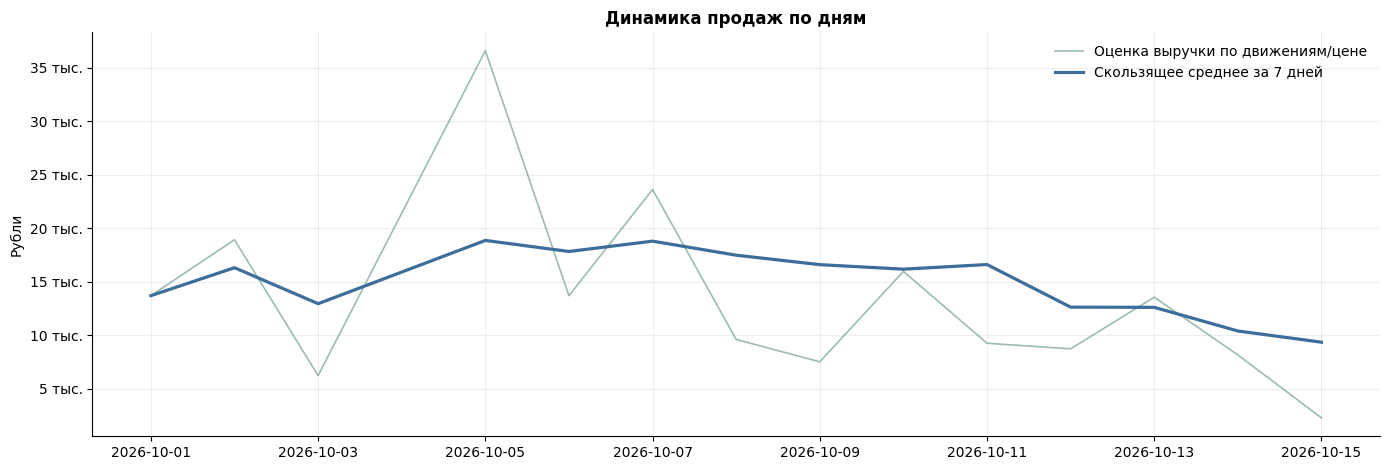

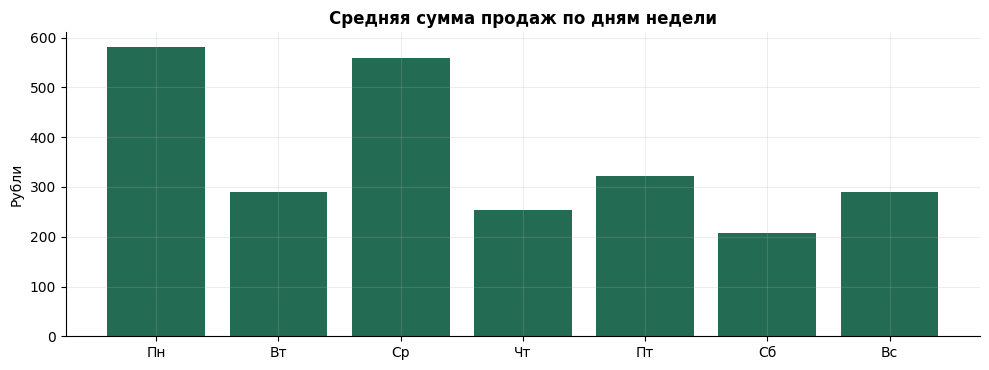

Источник динамики: оценочные суммы или неполные данные


In [8]:
# Для продукта используем фактическую сводку продаж, если она распознана.
if sales_summary is not None and len(sales_summary):
    product_sales = sales_summary.copy()
    product_sales["Ключ товара"] = product_sales["Ключ товара"].map(norm_text)
    product_sales["Выручка"] = to_num(product_sales["Выручка"])
    product_sales["Продано, шт"] = to_num(product_sales["Продано, шт"])
    if "Себестоимость" not in product_sales:
        product_sales["Себестоимость"] = np.nan
    # Если детальные строки считаются более надёжными и действительно содержат суммы по строкам, используем их для итогов.
    if sales_detail["Сумма из файла"].any() and sales_detail["Дата"].notna().any():
        detail_product = sales_detail.groupby("Ключ товара", as_index=False).agg(
            Товар=("Товар", "first"), **{"Продано, шт": ("Кол-во", "sum"), "Выручка": ("Выручка", "sum")}
        )
        cost_by_key = sales_detail.groupby("Ключ товара")["Себестоимость"].sum(min_count=1)
        detail_product["Себестоимость"] = detail_product["Ключ товара"].map(cost_by_key)
        # Берём детальные данные только если по ним достаточно распознанных фактических сумм.
        if sales_detail["Сумма из файла"].mean() >= 0.8:
            product_sales = detail_product
else:
    product_sales = sales_detail.groupby("Ключ товара", as_index=False).agg(
        Товар=("Товар", "first"), **{"Продано, шт": ("Кол-во", "sum"), "Выручка": ("Выручка", "sum"), "Себестоимость": ("Себестоимость", "sum")}
    ) if len(sales_detail) else pd.DataFrame(columns=["Ключ товара", "Товар", "Продано, шт", "Выручка", "Себестоимость"])

# Если сводка продаж не содержит надёжную себестоимость, пытаемся восстановить её из
# суммы себестоимости розничных расходных документов (минус себестоимость возвратов).
# Это сработает только если даты и документы движения подходят к выбранному периоду.
if len(product_sales):
    movement_sell = docs_period[docs_period["Это продажа"].fillna(False)].copy() if len(docs_period) else pd.DataFrame()
    movement_return = docs_period[docs_period["Это возврат"].fillna(False)].copy() if len(docs_period) else pd.DataFrame()
    if len(movement_sell):
        sold_cost = movement_sell.groupby("Ключ товара")["Расход себестоимость, ₽"].sum(min_count=1)
        returned_cost = movement_return.groupby("Ключ товара")["Приход, ₽"].sum(min_count=1) if len(movement_return) else pd.Series(dtype=float)
        net_movement_cost = sold_cost.sub(returned_cost, fill_value=0)
        if "Себестоимость" not in product_sales:
            product_sales["Себестоимость"] = np.nan
        missing_cost = product_sales["Себестоимость"].isna()
        product_sales.loc[missing_cost, "Себестоимость"] = product_sales.loc[missing_cost, "Ключ товара"].map(net_movement_cost)

product_sales["Маржа, ₽"] = product_sales["Выручка"] - product_sales["Себестоимость"]
product_sales["Маржа, %"] = safe_divide(product_sales["Маржа, ₽"], product_sales["Выручка"]) * 100
product_sales["Цена продажи"] = safe_divide(product_sales["Выручка"], product_sales["Продано, шт"])
product_sales["Категория"] = product_sales["Товар"].map(categorize)

# Если сводная сводка точная, выручка KPI берётся из неё. Динамика — из детальных строк, если данные есть.
revenue_total = float(product_sales["Выручка"].fillna(0).sum()) if len(product_sales) else 0.0
cost_total = float(product_sales["Себестоимость"].fillna(0).sum()) if len(product_sales) and product_sales["Себестоимость"].notna().any() else np.nan
margin_total = revenue_total - cost_total if pd.notna(cost_total) else np.nan
margin_pct_total = margin_total / revenue_total * 100 if pd.notna(margin_total) and revenue_total else np.nan
receipt_series = sales_detail.loc[sales_detail["Кол-во"] > 0, "Чек_ID"].replace("", np.nan).dropna() if len(sales_detail) else pd.Series(dtype=object)
n_checks = int(receipt_series.nunique())
avg_check = revenue_total / n_checks if n_checks > 0 else np.nan
items_per_check = sales_detail.loc[sales_detail["Кол-во"] > 0].groupby("Чек_ID")["Товар"].nunique().mean() if n_checks > 0 else np.nan

actual_revenue_flag = bool(len(sales_detail) and "Сумма из файла" in sales_detail and sales_detail["Сумма из файла"].mean() >= 0.95)
print("# 🌷 Краткая сводка")
summary_kpis = pd.DataFrame([
    {"Показатель": "Выручка по товарам", "Значение": money(revenue_total), "Комментарий": "Суммы из сводки продаж; проверьте период и фильтры"},
    {"Показатель": "Себестоимость проданного", "Значение": money(cost_total) if pd.notna(cost_total) else "нет данных", "Комментарий": "Только если себестоимость есть в источнике продаж"},
    {"Показатель": "Валовая маржа", "Значение": money(margin_total) if pd.notna(margin_total) else "нет данных", "Комментарий": "Выручка минус себестоимость; не чистая прибыль"},
    {"Показатель": "Валовая маржа, %", "Значение": percent(margin_pct_total), "Комментарий": "Сравнивайте одинаковые периоды и товарный состав"},
    {"Показатель": "Чеков", "Значение": number_fmt(n_checks), "Комментарий": "Только при наличии идентификатора каждого чека"},
    {"Показатель": "Средний чек", "Значение": money(avg_check) if pd.notna(avg_check) else "недостаточно данных", "Комментарий": "Не рассчитывается по сводке без номеров чеков"},
    {"Показатель": "Позиций в чеке", "Значение": f"{items_per_check:.2f}" if pd.notna(items_per_check) else "недостаточно данных", "Комментарий": "Считается только по детальным строкам с ID чека"},
])
display(summary_kpis)

# Динамика по дням. Если строки получены из «Движения товаров» с оценочной ценой, подпись это отражает.
valid_dated = sales_detail.dropna(subset=["Дата"]).copy() if len(sales_detail) else pd.DataFrame()
if len(valid_dated):
    valid_dated["День"] = valid_dated["Дата"].dt.normalize()
    daily = valid_dated.groupby("День").agg(
        Выручка=("Выручка", "sum"), Количество=("Кол-во", "sum"), Чеков=("Чек_ID", "nunique")
    ).reset_index()
    daily["Маржа, ₽"] = np.nan
    if valid_dated["Себестоимость"].notna().any():
        costs_day = valid_dated.groupby("День")["Себестоимость"].sum(min_count=1)
        daily["Маржа, ₽"] = daily["Выручка"] - daily["День"].map(costs_day)
    daily["MA7"] = daily["Выручка"].rolling(7, min_periods=1).mean()
    revenue_label = "Выручка по детальным строкам" if actual_revenue_flag else "Оценка выручки по движениям/цене"
    fig, ax = plt.subplots(figsize=(14, 4.8))
    ax.plot(daily["День"], daily["Выручка"], color=PALETTE[0], alpha=.45, linewidth=1.2, label=revenue_label)
    ax.plot(daily["День"], daily["MA7"], color=PALETTE[2], linewidth=2.3, label="Скользящее среднее за 7 дней")
    ax.set_title("Динамика продаж по дням")
    ax.set_ylabel("Рубли")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(rub_axis))
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()
    valid_dated["День недели"] = valid_dated["Дата"].dt.dayofweek
    dow = valid_dated.groupby("День недели").agg(Выручка=("Выручка", "mean"), Строк=("Выручка", "size")).reindex(range(7))
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.bar(DAYS_RU, dow["Выручка"].fillna(0), color=PALETTE[0])
    ax.set_title("Средняя сумма продаж по дням недели")
    ax.set_ylabel("Рубли")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(rub_axis))
    plt.tight_layout(); plt.show()
else:
    daily = pd.DataFrame(columns=["День", "Выручка", "Количество", "Чеков", "Маржа, ₽", "MA7"])
    print("ℹ️ Не удалось построить динамику по дням: в источнике не распознаны даты отдельных продаж.")

print("Источник динамики:", "фактические суммы в строках" if actual_revenue_flag else "оценочные суммы или неполные данные")

# 12. Ассортимент: ABC, XYZ и категории

- **ABC** показывает, какие товары дают основную часть выручки. Обычно товары A требуют постоянного контроля наличия, но границы 80/95% — рабочее правило, а не закон природы.
- **XYZ** оценивает стабильность спроса по неделям. Для надёжного XYZ желательно минимум 6–8 недель наблюдений. Если недель мало, результат условный.
- Категории определяются по ключевым словам в названии. Это автоматическая подсказка; проверьте спорные позиции вручную.

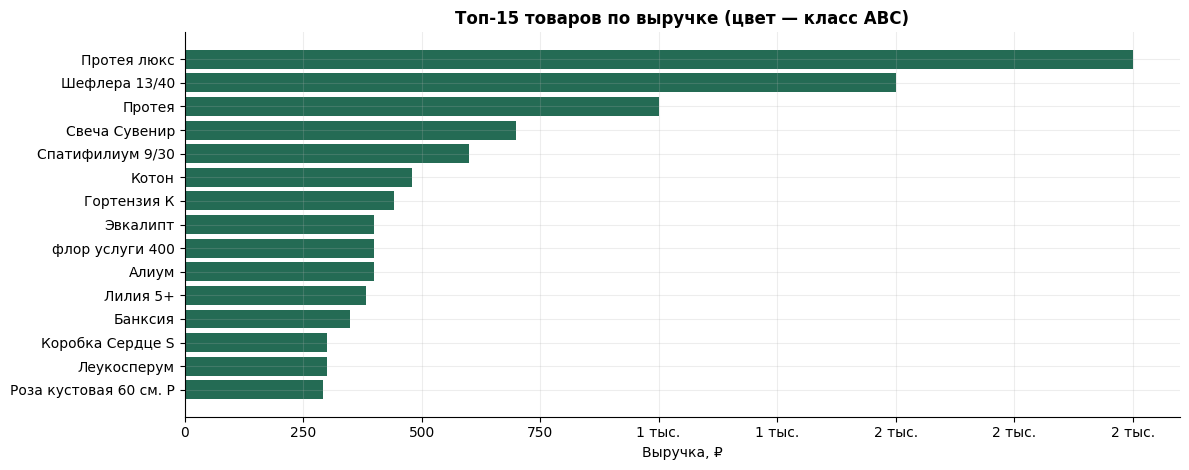

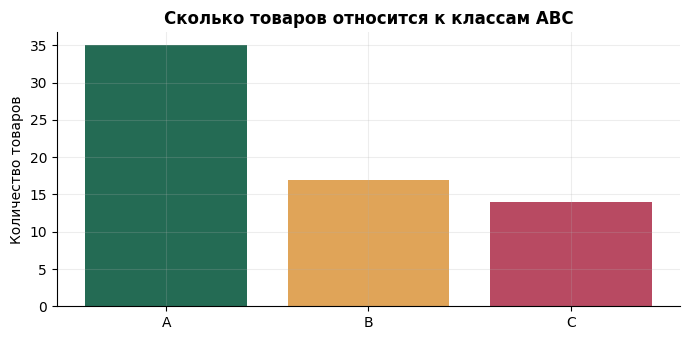

,Ключ товара,Товар,"Продано, шт",Выручка,Себестоимость,Цена продажи,Выручка из файла,"Маржа, ₽","Маржа, %",Категория,"Доля, %","Накопленная доля, %",Класс ABC,Среднее в неделю,"Коэффициент вариации, %",Класс XYZ,ABC×XYZ
0,протея люкс,Протея люкс,4.0,2000.00,5317.84,500.000000,True,-3317.84,-165.892000,Прочая срезка,10.982132,10.982132,A,1.333333,93.541435,Y,AY
1,шефлера 13/40,Шефлера 13/40,1.0,1500.00,792.00,1500.000000,True,708.00,47.200000,Горшечные растения,8.236599,19.218731,A,0.333333,141.421356,Z,AZ
2,протея,Протея,5.0,1000.00,2797.20,200.000000,True,-1797.20,-179.720000,Прочая срезка,5.491066,24.709797,A,1.666667,74.833148,Y,AY
3,свеча сувенир,Свеча Сувенир,1.0,700.00,281.78,700.000000,True,418.22,59.745714,Прочая срезка,3.843746,28.553543,A,0.333333,141.421356,Z,AZ
4,спатифилиум 9/30,Спатифилиум 9/30,1.0,600.00,376.00,600.000000,True,224.00,37.333333,Прочая срезка,3.294640,31.848183,A,0.333333,141.421356,Z,AZ
5,котон,Котон,1.0,480.00,280.00,480.000000,True,200.00,41.666667,Прочая срезка,2.635712,34.483895,A,0.333333,141.421356,Z,AZ
6,гортензия к,Гортензия К,49.0,442.65,10562.40,9.033673,True,-10119.75,-2286.174178,Прочая срезка,2.430620,36.914515,A,16.333333,65.242316,Y,AY
7,алиум,Алиум,9.0,400.00,3096.00,44.444444,True,-2696.00,-674.000000,Прочая срезка,2.196426,39.110941,A,3.000000,98.130676,Y,AY
8,эвкалипт,Эвкалипт,1.0,400.00,128.00,400.000000,True,272.00,68.000000,Зелень и наполнители,2.196426,41.307368,A,0.333333,141.421356,Z,AZ
9,флор услуги 400,флор услуги 400,13.0,400.00,13.00,30.769231,True,387.00,96.750000,Услуги,2.196426,43.503794,A,4.333333,110.405385,Z,AZ


ℹ️ XYZ рассчитан по 3 календарным неделям; интерпретируйте осторожно, если наблюдений мало.


,Категория,Выручка,Себестоимость,Товаров,Продано,"Маржа, ₽","Маржа, %"
2,Прочая срезка,11630.58,62930.11,37,499.0,-51299.53,-441.074564
3,Розы,1537.24,12839.00,7,991.0,-11301.76,-735.198147
0,Горшечные растения,1500.00,792.00,1,1.0,708.00,47.200000
6,Услуги,1039.17,159.00,5,159.0,880.17,84.699327
5,Упаковка и аксессуары,1012.92,1615.36,8,20.0,-602.44,-59.475576
1,Зелень и наполнители,707.69,2720.50,4,43.0,-2012.81,-284.419732
7,Хризантемы,633.80,43578.40,3,357.0,-42944.60,-6775.733670
4,Тюльпаны,150.00,8641.90,1,133.0,-8491.90,-5661.266667


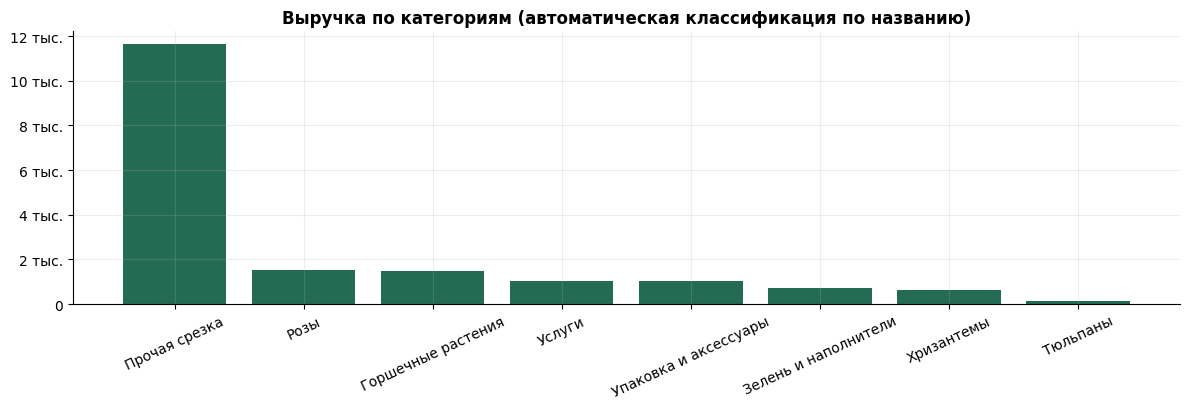

In [9]:
def add_abc_class(table, value_column, result_name="Класс ABC"):
    result = table.copy()
    values = result[value_column].fillna(0).clip(lower=0)
    total = values.sum()
    if total <= 0:
        result["Доля, %"] = 0.0
        result["Накопленная доля, %"] = 0.0
        result[result_name] = "C"
        return result
    result = result.sort_values(value_column, ascending=False).reset_index(drop=True)
    result["Доля, %"] = result[value_column].fillna(0).clip(lower=0) / total * 100
    result["Накопленная доля, %"] = result["Доля, %"].cumsum()
    # Класс определяется по накопленной доле до/включая порог.
    result[result_name] = np.select([result["Накопленная доля, %"] <= 80,
                                     result["Накопленная доля, %"] <= 95], ["A", "B"], default="C")
    return result

if len(product_sales):
    abc = add_abc_class(product_sales, "Выручка")
    # XYZ по недельным количествам, если есть даты.
    if len(valid_dated) and valid_dated["Дата"].notna().sum() >= 10:
        weekly = valid_dated[valid_dated["Кол-во"] > 0].copy()
        weekly["Неделя"] = weekly["Дата"].dt.to_period("W").dt.start_time
        weekly_table = weekly.pivot_table(index="Ключ товара", columns="Неделя", values="Кол-во", aggfunc="sum", fill_value=0)
        mean_qty = weekly_table.mean(axis=1)
        std_qty = weekly_table.std(axis=1, ddof=0)
        cv = (std_qty / mean_qty.replace(0, np.nan) * 100).replace([np.inf, -np.inf], np.nan)
        xyz = pd.DataFrame({"Ключ товара": weekly_table.index, "Среднее в неделю": mean_qty.values, "Коэффициент вариации, %": cv.values})
        xyz["Класс XYZ"] = np.select([xyz["Коэффициент вариации, %"] <= 50,
                                      xyz["Коэффициент вариации, %"] <= 100], ["X", "Y"], default="Z")
        xyz.loc[xyz["Среднее в неделю"] <= 0, "Класс XYZ"] = "Z"
        abc = abc.merge(xyz, on="Ключ товара", how="left")
        abc["Класс XYZ"] = abc["Класс XYZ"].fillna("Z")
        abc["ABC×XYZ"] = abc["Класс ABC"] + abc["Класс XYZ"]
        xyz_message = f"XYZ рассчитан по {weekly_table.shape[1]} календарным неделям; интерпретируйте осторожно, если наблюдений мало."
    else:
        abc["Класс XYZ"] = "нет данных"
        abc["ABC×XYZ"] = "нет данных"
        xyz_message = "Для XYZ не хватает детальных датированных продаж; показатель не рассчитывался."
    abc["Категория"] = abc["Товар"].map(categorize)
    fig, ax = plt.subplots(figsize=(12, max(4, .32 * min(TOP_N, len(abc)))))
    top = abc.head(TOP_N).sort_values("Выручка", ascending=True)
    ax.barh(top["Товар"], top["Выручка"], color=[ABC_COLORS.get(x, PALETTE[0]) for x in top["Класс ABC"]])
    ax.set_title(f"Топ-{min(TOP_N, len(abc))} товаров по выручке (цвет — класс ABC)")
    ax.set_xlabel("Выручка, ₽"); ax.xaxis.set_major_formatter(mticker.FuncFormatter(rub_axis))
    plt.tight_layout(); plt.show()
    abc_counts = abc["Класс ABC"].value_counts().reindex(["A", "B", "C"]).fillna(0)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.bar(abc_counts.index, abc_counts.values, color=[ABC_COLORS[k] for k in abc_counts.index])
    ax.set_title("Сколько товаров относится к классам ABC")
    ax.set_ylabel("Количество товаров")
    plt.tight_layout(); plt.show()
    display(abc.head(20))
    print("ℹ️", xyz_message)
else:
    abc = pd.DataFrame(columns=["Ключ товара", "Товар", "Выручка", "Класс ABC", "Класс XYZ", "ABC×XYZ"])
    print("ℹ️ Нет достаточных сведений о продажах товаров для ABC/XYZ.")

if len(product_sales):
    category_sales = product_sales.groupby("Категория", as_index=False).agg(
        Выручка=("Выручка", "sum"), Себестоимость=("Себестоимость", "sum"), Товаров=("Товар", "nunique"), Продано=("Продано, шт", "sum")
    )
    category_sales["Маржа, ₽"] = category_sales["Выручка"] - category_sales["Себестоимость"]
    category_sales["Маржа, %"] = safe_divide(category_sales["Маржа, ₽"], category_sales["Выручка"]) * 100
    category_sales = category_sales.sort_values("Выручка", ascending=False)
    display(category_sales)
    fig, ax = plt.subplots(figsize=(12, 4.2))
    ax.bar(category_sales["Категория"], category_sales["Выручка"], color=PALETTE[0])
    ax.set_title("Выручка по категориям (автоматическая классификация по названию)")
    ax.tick_params(axis="x", rotation=25); ax.yaxis.set_major_formatter(mticker.FuncFormatter(rub_axis))
    plt.tight_layout(); plt.show()
else:
    category_sales = pd.DataFrame(columns=["Категория", "Выручка", "Маржа, ₽", "Маржа, %"])

# 13. Чеки и допродажи: что покупают вместе

Market Basket — анализ корзины: какие пары товаров встречаются в одном чеке. Он полезен, чтобы предлагать к розам открытку, упаковку или зелень. Этот раздел выполняется только если в данных есть **настоящий идентификатор каждого чека**. Если в колонке «Документ» номер сводного отчёта, а не кассового чека, использовать такой анализ нельзя.

In [10]:
market_basket = pd.DataFrame(columns=["Товар A", "Товар B", "Вместе чеков", "Поддержка, %", "Лифт"])
if len(sales_detail) and sales_detail["Чек_ID"].replace("", np.nan).notna().any():
    basket_source = sales_detail[(sales_detail["Кол-во"] > 0) & sales_detail["Чек_ID"].replace("", np.nan).notna()].copy()
    basket_source["Товар"] = basket_source["Товар"].astype(str).str.strip()
    basket_by_check = basket_source.groupby("Чек_ID")["Товар"].agg(lambda s: sorted(set(x for x in s if x and x.lower() != "nan")))
    n_baskets = len(basket_by_check)
    counts = Counter()
    item_counts = Counter()
    for items in basket_by_check:
        item_counts.update(items)
        counts.update(combinations(items, 2))
    rows = []
    for (a, b), n_together in counts.items():
        if n_together < MIN_PAIR_COUNT:
            continue
        support = n_together / n_baskets if n_baskets else 0
        conf = n_together / item_counts[a] if item_counts[a] else 0
        conf_b = n_together / item_counts[b] if item_counts[b] else 0
        lift = support / ((item_counts[a] / n_baskets) * (item_counts[b] / n_baskets)) if n_baskets else np.nan
        rows.append({"Товар A": a, "Товар B": b, "Вместе чеков": n_together,
                     "Поддержка, %": support * 100, "Лифт": lift,
                     "Вероятность B при A, %": conf * 100, "Вероятность A при B, %": conf_b * 100})
    market_basket = pd.DataFrame(rows)
    if len(market_basket):
        market_basket = market_basket.sort_values(["Лифт", "Вместе чеков"], ascending=False)
        display(market_basket.head(20))
        print("Как читать: «Вместе чеков» — сколько чеков содержат пару; «Лифт» > 1 указывает на связь чаще случайной. Это не доказывает причинность.")
    else:
        print(f"ℹ️ Найдено {n_baskets} чеков, но пар, достигших MIN_PAIR_COUNT={MIN_PAIR_COUNT}, нет.")
else:
    print("ℹ️ Market Basket пропущен: нет достоверного ID каждого чека. Сводка по товарам не позволяет восстановить состав покупок.")

,Товар A,Товар B,Вместе чеков,"Поддержка, %",Лифт,"Вероятность B при A, %","Вероятность A при B, %"
7,Оазис,Сумки средние,6,2.307692,28.888889,66.666667,100.000000
6,Оазис,Скимия,3,1.153846,12.380952,33.333333,42.857143
41,Альстрамерия,Клематис,3,1.153846,11.818182,13.636364,100.000000
22,Гелиантус,Гортензия К,3,1.153846,9.176471,60.000000,17.647059
19,Вакс-флаур,Гортензия К,7,2.692308,8.235294,53.846154,41.176471
16,Альстрамерия,Гелиантус,3,1.153846,7.090909,13.636364,60.000000
20,Вакс-флаур,Оазис,3,1.153846,6.666667,23.076923,33.333333
44,Вакс-флаур,флор услуги 200,3,1.153846,6.000000,23.076923,30.000000
5,Альстрамерия,Сумки средние,3,1.153846,5.909091,13.636364,50.000000
58,Альстрамерия,Папортник,3,1.153846,5.909091,13.636364,50.000000


Как читать: «Вместе чеков» — сколько чеков содержат пару; «Лифт» > 1 указывает на связь чаще случайной. Это не доказывает причинность.


# 14. Маржа, остатки и ориентир закупки

Валовая маржа — это **выручка минус себестоимость проданного товара**. Это не чистая прибыль: здесь не вычтены аренда, зарплата, эквайринг, налоги, доставка и прочие расходы.

Для цветочного магазина закупочный ориентир должен быть коротким и осторожным: цветы быстро теряют товарный вид. Код ниже использует средние продажи последних `COVER_LOOKBACK` дней и сравнивает их с учётным остатком. Результат — подсказка для человека, а не автоматический заказ поставщику.

In [11]:
# Свод по товарам + складская информация.
if len(product_sales):
    product_report = product_sales.copy()
    stock_cols = ["Ключ товара", "Начальный остаток", "Приход, шт", "Приход, ₽", "Расход, шт", "Расход себестоимость, ₽", "Конечный остаток", "Остаток, ₽", "Учётная невязка, шт"]
    stock_for_join = stock[[c for c in stock_cols if c in stock.columns]].drop_duplicates("Ключ товара") if len(stock) else pd.DataFrame(columns=["Ключ товара"])
    product_report = product_report.merge(stock_for_join, on="Ключ товара", how="left", suffixes=("", "_склад"))
else:
    product_report = stock.copy()
    for c in ["Выручка", "Продано, шт", "Себестоимость", "Маржа, ₽", "Маржа, %", "Цена продажи"]:
        if c not in product_report:
            product_report[c] = np.nan

if len(product_report):
    if "Маржа, ₽" not in product_report:
        product_report["Маржа, ₽"] = product_report["Выручка"] - product_report["Себестоимость"]
    if "Маржа, %" not in product_report:
        product_report["Маржа, %"] = safe_divide(product_report["Маржа, ₽"], product_report["Выручка"]) * 100
    if "Остаток, ₽" not in product_report:
        product_report["Остаток, ₽"] = np.nan
    product_report["Проверить маржу"] = (product_report["Маржа, ₽"] < 0) | (product_report["Маржа, %"] < MARGIN_TARGET)
    display(product_report.sort_values("Выручка", ascending=False).head(20))

# Продажи по товару за последние COVER_LOOKBACK дней — скорость для закупки.
if len(sales_detail) and sales_detail["Дата"].notna().any():
    latest_day = sales_detail["Дата"].max().normalize()
    lookback_start = latest_day - pd.Timedelta(days=COVER_LOOKBACK - 1)
    recent = sales_detail[(sales_detail["Дата"] >= lookback_start) & (sales_detail["Дата"] < latest_day + pd.Timedelta(days=1)) & (sales_detail["Кол-во"] > 0)]
    recent_sales = recent.groupby("Ключ товара")["Кол-во"].sum()
    observed_days = max(1, min(COVER_LOOKBACK, (latest_day - sales_detail["Дата"].min().normalize()).days + 1))
else:
    latest_day = analysis_end.normalize()
    recent_sales = pd.Series(dtype=float)
    observed_days = max(1, (analysis_end.normalize() - analysis_start.normalize()).days + 1)

stock_view = stock.copy()
stock_view["Продано за окно, шт"] = stock_view["Ключ товара"].map(recent_sales).fillna(0)
stock_view["Продаж в день, шт"] = stock_view["Продано за окно, шт"] / observed_days
stock_view["Запас на целевое покрытие, шт"] = stock_view["Продаж в день, шт"] * COVER_DAYS
stock_view["Рекомендация к закупке, шт"] = np.ceil((stock_view["Запас на целевое покрытие, шт"] - stock_view["Конечный остаток"].fillna(0)).clip(lower=0))
stock_view["Деньги в остатках, ₽"] = stock_view["Остаток, ₽"]
stock_view["Категория"] = stock_view["Товар"].map(categorize)

if len(sales_detail) and sales_detail["Дата"].notna().any():
    last_sale = sales_detail[sales_detail["Кол-во"] > 0].groupby("Ключ товара")["Дата"].max()
    stock_view["Последняя продажа"] = stock_view["Ключ товара"].map(last_sale)
    stock_view["Дней без продаж"] = (latest_day - stock_view["Последняя продажа"].dt.normalize()).dt.days
    stock_view.loc[stock_view["Последняя продажа"].isna(), "Дней без продаж"] = (latest_day - analysis_start.normalize()).days + 1
else:
    stock_view["Последняя продажа"] = pd.NaT
    stock_view["Дней без продаж"] = np.nan

slow_stock = stock_view[(stock_view["Конечный остаток"].fillna(0) > 0) & (stock_view["Дней без продаж"] >= SLOW_DAYS)].sort_values("Остаток, ₽", ascending=False)
buy_plan = stock_view[stock_view["Рекомендация к закупке, шт"] > 0].sort_values("Рекомендация к закупке, шт", ascending=False)

print(f"💰 Стоимость остатков по отчёту (если стоимость заполнена): {money(stock_view['Остаток, ₽'].sum(min_count=1))}")
print(f"🧊 Позиций с остатком без продаж {SLOW_DAYS}+ дней: {len(slow_stock)}")
if len(slow_stock):
    display(slow_stock[["Товар", "Конечный остаток", "Остаток, ₽", "Дней без продаж"]].head(15))
else:
    print("Нет товаров, которые одновременно имеют остаток и подтверждённый период без продаж, либо не хватает дат.")
print(f"🛒 Позиций в ориентире закупки: {len(buy_plan)}. Покрытие = {COVER_DAYS} дня, скорость = последние {COVER_LOOKBACK} дней.")
if len(buy_plan):
    display(buy_plan[["Товар", "Конечный остаток", "Продаж в день, шт", "Запас на целевое покрытие, шт", "Рекомендация к закупке, шт"]].head(20))
print("⚠️ Учитывайте срок жизни сорта, прогноз погоды/праздников, минимальную партию поставщика и время доставки. Для товаров без продаж рекомендация равна нулю, а не случайному числу.")

,Ключ товара,Товар,"Продано, шт",Выручка,Себестоимость,Цена продажи,Выручка из файла,"Маржа, ₽","Маржа, %",Категория,Начальный остаток,"Приход, шт","Приход, ₽","Расход, шт","Расход себестоимость, ₽",Конечный остаток,"Остаток, ₽","Учётная невязка, шт",Проверить маржу
38,протея люкс,Протея люкс,4.0,2000.00,5317.84,500.000000,True,-3317.84,-165.892000,Прочая срезка,0.0,5.0,6647.30,5.0,6647.30,0.0,0.00,0.0,True
64,шефлера 13/40,Шефлера 13/40,1.0,1500.00,792.00,1500.000000,True,708.00,47.200000,Горшечные растения,3.0,0.0,0.00,1.0,792.00,2.0,1672.00,0.0,False
37,протея,Протея,5.0,1000.00,2797.20,200.000000,True,-1797.20,-179.720000,Прочая срезка,6.0,3.0,1518.88,5.0,2797.20,4.0,2078.32,0.0,True
47,свеча сувенир,Свеча Сувенир,1.0,700.00,281.78,700.000000,True,418.22,59.745714,Прочая срезка,2.0,0.0,0.00,1.0,281.78,1.0,372.53,0.0,False
49,спатифилиум 9/30,Спатифилиум 9/30,1.0,600.00,376.00,600.000000,True,224.00,37.333333,Прочая срезка,4.0,0.0,0.00,1.0,376.00,3.0,1899.18,0.0,True
21,котон,Котон,1.0,480.00,280.00,480.000000,True,200.00,41.666667,Прочая срезка,14.0,0.0,0.00,1.0,280.00,13.0,3640.00,0.0,False
13,гортензия к,Гортензия К,49.0,442.65,10562.40,9.033673,True,-10119.75,-2286.174178,Прочая срезка,64.0,46.0,9825.60,67.0,14471.20,43.0,9237.27,0.0,True
0,алиум,Алиум,9.0,400.00,3096.00,44.444444,True,-2696.00,-674.000000,Прочая срезка,9.0,0.0,0.00,9.0,3096.00,0.0,0.00,0.0,True
65,эвкалипт,Эвкалипт,1.0,400.00,128.00,400.000000,True,272.00,68.000000,Зелень и наполнители,11.0,44.0,5632.00,1.0,128.00,54.0,6920.00,0.0,False
58,флор услуги 400,флор услуги 400,13.0,400.00,13.00,30.769231,True,387.00,96.750000,Услуги,12.0,501.0,501.00,13.0,13.00,500.0,501.00,0.0,False


💰 Стоимость остатков по отчёту (если стоимость заполнена): 400 016 ₽
🧊 Позиций с остатком без продаж 21+ дней: 0
Нет товаров, которые одновременно имеют остаток и подтверждённый период без продаж, либо не хватает дат.
🛒 Позиций в ориентире закупки: 17. Покрытие = 4 дня, скорость = последние 28 дней.


,Товар,Конечный остаток,"Продаж в день, шт","Запас на целевое покрытие, шт","Рекомендация к закупке, шт"
221,"Кустовая роза Кения, шт. Размер: 60",0.0,6.933333,27.733333,28.0
326,"Роза микс Э, шт. Размер: 50",0.0,6.466667,25.866667,26.0
430,Хризантема одноголовая К,43.0,15.933333,63.733333,21.0
335,"Роза пионовидная Э, шт. размер: 60",0.0,3.133333,12.533333,13.0
328,"Роза микс Э, шт. Размер: 70",0.0,2.600000,10.400000,11.0
330,"Роза микс, шт. Размер: 50",0.0,2.333333,9.333333,10.0
95,Гипсофила,0.0,1.733333,6.933333,7.0
11,Алиум,0.0,0.600000,2.400000,3.0
220,"Кустовая роза Кения, шт. Размер: 50",0.0,0.600000,2.400000,3.0
103,Грин трик,0.0,0.466667,1.866667,2.0


⚠️ Учитывайте срок жизни сорта, прогноз погоды/праздников, минимальную партию поставщика и время доставки. Для товаров без продаж рекомендация равна нулю, а не случайному числу.


# 15. Сигналы для проверки: склад, списания, возвраты, цены

Этот раздел не «вычисляет вора». Он формирует короткий список мест, которые менеджеру стоит проверить по первичным документам. На небольшом количестве данных статистические сигналы нестабильны, поэтому часть проверок честно пропускается, если недостаточно наблюдений.

In [12]:
alerts = []
def add_alert(check, obj, metric, reason, next_step, severity="Проверить"):
    alerts.append({"Приоритет": severity, "Проверка": check, "Объект": str(obj), "Показатель": str(metric),
                   "Почему смотреть": reason, "Следующий шаг": next_step})

# 15.1 Учётная формула движения: полезна для поиска ошибок отчёта, но не заменяет пересчёт физического остатка.
if len(stock) and "Учётная невязка, шт" in stock.columns:
    bad_balance = stock[stock["Учётная невязка, шт"].abs() > 0.5]
    for _, r in bad_balance.iterrows():
        add_alert("Внутренняя невязка движения", r["Товар"], f"{r['Учётная невязка, шт']:+.1f} шт",
                  "Начальный остаток + приход − расход не равен конечному остатку в выгрузке.",
                  "Проверить единицы измерения, фильтр склада, перемещения, даты и исходный отчёт.", "Высокий")
    neg = stock[stock["Конечный остаток"] < -0.001]
    for _, r in neg.iterrows():
        add_alert("Отрицательный остаток", r["Товар"], f"{r['Конечный остаток']:.1f} шт",
                  "Отрицательный учётный остаток может искажать себестоимость и продажи.",
                  "Проверить дату оформления прихода, пересортицу, единицы и склад.", "Высокий")

# 15.2 Пики списаний по дням.
writeoff_docs = docs_period[docs_period["Это списание"].fillna(False)].copy() if len(docs_period) else pd.DataFrame()
if len(writeoff_docs) and writeoff_docs["Дата"].notna().any():
    writeoff_docs["День"] = writeoff_docs["Дата"].dt.normalize()
    writeoff_docs["Сумма списания, ₽"] = to_num(writeoff_docs["Расход себестоимость, ₽"]).fillna(0).abs()
    writeoff_daily = writeoff_docs.groupby("День")["Сумма списания, ₽"].sum().sort_index()
    if len(writeoff_daily) >= 5:
        median = writeoff_daily.median()
        mad = (writeoff_daily - median).abs().median()
        robust_scale = 1.4826 * mad
        if robust_scale > 0:
            spike_days = writeoff_daily[(writeoff_daily - median) / robust_scale > 3]
        else:
            spike_days = writeoff_daily[writeoff_daily > max(median * 2, median + 0.01)]
        if len(writeoff_daily):
            fig, ax = plt.subplots(figsize=(13, 3.8))
            ax.bar(writeoff_daily.index, writeoff_daily.values, color=PALETTE[3], alpha=.8)
            ax.axhline(median, color=PALETTE[2], linestyle="--", label=f"Медиана: {money(median)}")
            ax.set_title("Списания по дням (себестоимость по движению)")
            ax.set_ylabel("Рубли"); ax.yaxis.set_major_formatter(mticker.FuncFormatter(rub_axis)); ax.legend(frameon=False)
            plt.tight_layout(); plt.show()
        for day, value in spike_days.items():
            add_alert("Пик списаний", day.strftime("%d.%m.%Y"), money(value),
                      f"Сумма за день необычно высока относительно истории (медиана {money(median)}).",
                      "Сверить акты, фото порчи, количество, причины и дату создания документов.", "Высокий")
    else:
        print("ℹ️ Для статистического поиска пиков списаний нужно хотя бы 5 дат с документами списания.")
    # Товары, списанные в больших количествах, выводим отдельно для ручной проверки.
    writeoff_by_item = writeoff_docs.groupby("Товар").agg(
        Документов=("Документ", "nunique"), **{"Списано, шт": ("Расход, шт", "sum"), "Себестоимость списаний, ₽": ("Расход себестоимость, ₽", "sum")}
    ).sort_values("Себестоимость списаний, ₽", ascending=False)
    print("Топ товаров по списаниям:")
    display(writeoff_by_item.head(15))
else:
    writeoff_daily = pd.Series(dtype=float)
    print("ℹ️ В движении не найдено датированных документов списания. Проверьте фильтры/отдельный отчёт «Списания».")

# 15.3 Цены заметно ниже медианы данного товара — только если фактическая сумма/цена есть в детализации.
if len(sales_detail) and "Цена" in sales_detail and sales_detail["Сумма из файла"].any():
    price_data = sales_detail[(sales_detail["Кол-во"] > 0) & sales_detail["Цена"].notna()].copy()
    if len(price_data):
        median_prices = price_data.groupby("Ключ товара")["Цена"].median()
        price_data["Медианная цена товара"] = price_data["Ключ товара"].map(median_prices)
        price_data["Отклонение цены, %"] = (price_data["Цена"] / price_data["Медианная цена товара"] - 1) * 100
        low_price = price_data[price_data["Отклонение цены, %"] <= -PRICE_ALERT_PCT]
        for _, r in low_price.iterrows():
            add_alert("Цена ниже медианы товара", f"{r['Товар']} · {r['Дата']:%d.%m.%Y}" if pd.notna(r["Дата"]) else r["Товар"],
                      f"{r['Отклонение цены, %']:.1f}%", "Цена позиции заметно ниже обычной медианы того же товара.",
                      "Проверить акцию, согласованную скидку, уценку увядшего цветка и исходный чек.")
else:
    print("ℹ️ Контроль цен пропущен: нужны детальные продажи с ценой/суммой позиции из файла, а не расчётная цена.")

# 15.4 Всплески возвратов.
if len(sales_detail) and "Возврат" in sales_detail and sales_detail["Возврат"].fillna(False).any() and sales_detail["Дата"].notna().any():
    sales_detail["День"] = sales_detail["Дата"].dt.normalize()
    checks_day = sales_detail[sales_detail["Кол-во"] > 0].groupby("День")["Чек_ID"].nunique()
    returns_day = sales_detail[sales_detail["Возврат"].fillna(False)].groupby("День")["Чек_ID"].nunique()
    returns_rate = (returns_day / checks_day.replace(0, np.nan) * 100).dropna()
    if len(returns_rate) >= 5:
        med_rate = returns_rate.median()
        for day, rate in returns_rate[returns_rate > max(med_rate * 2, med_rate + 5)].items():
            add_alert("Необычная доля возвратов", day.strftime("%d.%m.%Y"), f"{rate:.1f}%",
                      f"Доля чеков с возвратом выше обычной (медиана {med_rate:.1f}%).",
                      "Проверить причины возвратов, исходные чеки и согласование возврата.")
else:
    print("ℹ️ Сигнал по возвратам пропущен: в выгрузке нет явно отмеченных возвратов.")

# 15.5 Физическая инвентаризация — только если явно найдены колонки фактического и учётного остатка.
physical_inventory = None
if inventory_path is not None:
    raw_inv = extra_raw.get("Исходная таблица инвентаризации")
    inv_df, inv_header_row = table_with_detected_header(raw_inv) if raw_inv is not None else (None, None)
    if inv_df is not None:
        inv_item_col = find_column(inv_df.columns, prefer=("наименование товара", "товар", "номенклатура", "наименование"))
        book_col = find_column(inv_df.columns, prefer=("учетный остаток", "остаток по учету", "по данным учета", "количество по учету", "учетное количество"))
        fact_col = find_column(inv_df.columns, prefer=("фактический остаток", "фактическое количество", "факт количество", "фактически"))
        if inv_item_col and book_col and fact_col:
            physical_inventory = pd.DataFrame({
                "Товар": inv_df[inv_item_col].astype(str).str.strip(),
                "Учётный остаток": to_num(inv_df[book_col]),
                "Фактический остаток": to_num(inv_df[fact_col]),
            })
            physical_inventory = physical_inventory.dropna(subset=["Учётный остаток", "Фактический остаток"])
            physical_inventory["Недостача/излишек, шт"] = physical_inventory["Фактический остаток"] - physical_inventory["Учётный остаток"]
            physical_inventory["Ключ товара"] = physical_inventory["Товар"].map(norm_text)
            for _, r in physical_inventory[physical_inventory["Недостача/излишек, шт"].abs() > 0.001].iterrows():
                add_alert("Расхождение физической инвентаризации", r["Товар"], f"{r['Недостача/излишек, шт']:+.1f} шт",
                          "Фактическое количество отличается от учётного в таблице инвентаризации.",
                          "Повторно пересчитать, проверить единицу измерения и документы периода.", "Высокий")
            display(physical_inventory.sort_values("Недостача/излишек, шт").head(20))
        else:
            print("⚠️ Файл инвентаризации прочитан, но названия колонок учётного и фактического остатка не распознаны автоматически.")
            print("   Проверьте таблицу и при необходимости сопоставьте эти колонки вручную. Нельзя считать отсутствие сигнала подтверждением, что недостачи нет.")

alerts_df = pd.DataFrame(alerts, columns=["Приоритет", "Проверка", "Объект", "Показатель", "Почему смотреть", "Следующий шаг"])
if len(alerts_df):
    order_map = {"Высокий": 0, "Проверить": 1}
    alerts_df["_сортировка"] = alerts_df["Приоритет"].map(order_map).fillna(2)
    alerts_df = alerts_df.sort_values(["_сортировка", "Проверка"]).drop(columns="_сортировка").reset_index(drop=True)
    print(f"🔎 Сигналов для проверки: {len(alerts_df)}")
    display(alerts_df)
else:
    print("✅ По доступным данным явных сигналов не сформировано. Это не доказывает отсутствие ошибок или потерь: многое зависит от полноты выгрузок.")

ℹ️ В движении не найдено датированных документов списания. Проверьте фильтры/отдельный отчёт «Списания».
ℹ️ Контроль цен пропущен: нужны детальные продажи с ценой/суммой позиции из файла, а не расчётная цена.
ℹ️ Сигнал по возвратам пропущен: в выгрузке нет явно отмеченных возвратов.
✅ По доступным данным явных сигналов не сформировано. Это не доказывает отсутствие ошибок или потерь: многое зависит от полноты выгрузок.


# 16. Простой прогноз выручки и проверка точности

Для новичка используем базовый ориентир: медианная выручка за последние недели для такого же дня недели. Это не сложная ML-модель и она не знает о праздниках, погоде, рекламных акциях или внезапном изменении цен. Она подходит как первая точка сравнения, а не как автоматическое решение о закупке.

In [13]:
forecast_table = pd.DataFrame(columns=["Дата", "Прогноз, ₽"])
forecast_metrics = pd.DataFrame(columns=["Метрика", "Значение"])
if len(daily) >= 21 and daily["Выручка"].notna().sum() >= 21:
    history = daily.set_index("День")["Выручка"].sort_index().asfreq("D", fill_value=0)
    def predict_same_weekday(hist, target_date, weeks=8):
        relevant = hist[(hist.index < target_date) & (hist.index.dayofweek == target_date.dayofweek)].tail(weeks)
        if len(relevant):
            return float(relevant.median())
        return float(hist.tail(28).median()) if len(hist) else 0.0
    test_days = history.index[-14:]
    bt_rows = []
    for day in test_days:
        train = history[history.index < day]
        pred = predict_same_weekday(train, day)
        bt_rows.append({"Дата": day, "Факт": history.loc[day], "Прогноз": pred})
    backtest = pd.DataFrame(bt_rows)
    denominator = backtest["Факт"].abs().sum()
    wape = (backtest["Факт"] - backtest["Прогноз"]).abs().sum() / denominator * 100 if denominator else np.nan
    forecast_dates = pd.date_range(history.index.max() + pd.Timedelta(days=1), periods=FORECAST_DAYS, freq="D")
    forecast_table = pd.DataFrame({"Дата": forecast_dates, "Прогноз, ₽": [predict_same_weekday(history, d) for d in forecast_dates]})
    forecast_metrics = pd.DataFrame([
        {"Метрика": "WAPE на последних 14 днях, %", "Значение": round(wape, 1) if pd.notna(wape) else np.nan},
        {"Метрика": "Прогноз на горизонт, ₽", "Значение": round(forecast_table["Прогноз, ₽"].sum(), 2)},
        {"Метрика": "Средний прогноз в день, ₽", "Значение": round(forecast_table["Прогноз, ₽"].mean(), 2)},
    ])
    fig, ax = plt.subplots(figsize=(13, 4.5))
    history_show = history.tail(60)
    ax.plot(history_show.index, history_show.values, label="История", color=PALETTE[0])
    ax.plot(forecast_table["Дата"], forecast_table["Прогноз, ₽"], label="Простой прогноз", color=PALETTE[1], marker="o")
    ax.set_title(f"Ориентир выручки на {FORECAST_DAYS} дней")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(rub_axis)); ax.legend(frameon=False)
    plt.tight_layout(); plt.show()
    display(forecast_metrics)
    print("Прогноз нужно сравнить с наивным ориентиром и поправить на праздничные пики (14 февраля, 8 марта, День матери и локальные события).")
else:
    print("ℹ️ Прогноз пропущен: желательно не менее 3 недель датированной динамики. Для сезонной цветочной модели лучше иметь 12 месяцев и более.")

ℹ️ Прогноз пропущен: желательно не менее 3 недель датированной динамики. Для сезонной цветочной модели лучше иметь 12 месяцев и более.


# 17. Итог: что проверить в первую очередь

Ниже — короткий управленческий итог. Он специально не назначает виновных: он предлагает, где владелец/администратор может проверить первичные документы.

In [14]:
summary_rows = [
    {"Показатель": "Выручка по товарам", "Значение": money(revenue_total), "Как трактовать": "Проверьте, фактические ли суммы содержатся в источнике продаж."},
    {"Показатель": "Валовая маржа", "Значение": money(margin_total) if pd.notna(margin_total) else "нет данных", "Как трактовать": "Не путать с чистой прибылью."},
    {"Показатель": "Чеки", "Значение": number_fmt(n_checks), "Как трактовать": "Счётчик полезен только при настоящем ID чека."},
    {"Показатель": "Товарных позиций", "Значение": number_fmt(len(product_sales)), "Как трактовать": "Количество SKU с распознанными данными о продажах."},
    {"Показатель": "Товаров с остатком без продаж", "Значение": str(len(slow_stock)), "Как трактовать": f"Нет продаж не менее {SLOW_DAYS} дней; проверьте свежесть и корректность номенклатуры."},
    {"Показатель": "Позиций к возможному заказу", "Значение": str(len(buy_plan)), "Как трактовать": f"Ориентир на покрытие {COVER_DAYS} дней, а не готовый заказ поставщику."},
    {"Показатель": "Сигналов для проверки", "Значение": str(len(alerts_df)), "Как трактовать": "Каждый сигнал требует подтверждения документами."},
    {"Показатель": "Источник данных", "Значение": "ДЕМО" if DEMO_MODE else "Бизнес.Ру", "Как трактовать": "Демо-данные не описывают ваш магазин."},
]
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

print("\nПлан действий на ближайшую неделю")
print("1. Сверьте один и тот же период и одну розничную точку во всех выгрузках.")
print("2. Возьмите 10 самых дорогих/ходовых товаров и пересчитайте их независимо от сотрудников смены.")
print("3. Проверьте каждый крупный сигнал по чеку, документу, причине списания и фактическому количеству.")
print("4. Введите понятные правила возвратов, скидок и списаний; записывайте причины и согласование.")
print("5. После 4–8 недель регулярных выгрузок анализируйте тренды, а не единичные пики.")

,Показатель,Значение,Как трактовать
0,Выручка по товарам,18 211 ₽,"Проверьте, фактические ли суммы содержатся в и..."
1,Валовая маржа,-115 065 ₽,Не путать с чистой прибылью.
2,Чеки,260,Счётчик полезен только при настоящем ID чека.
3,Товарных позиций,66,Количество SKU с распознанными данными о прода...
4,Товаров с остатком без продаж,0,Нет продаж не менее 21 дней; проверьте свежест...
5,Позиций к возможному заказу,17,"Ориентир на покрытие 4 дней, а не готовый зака..."
6,Сигналов для проверки,0,Каждый сигнал требует подтверждения документами.
7,Источник данных,Бизнес.Ру,Демо-данные не описывают ваш магазин.



План действий на ближайшую неделю
1. Сверьте один и тот же период и одну розничную точку во всех выгрузках.
2. Возьмите 10 самых дорогих/ходовых товаров и пересчитайте их независимо от сотрудников смены.
3. Проверьте каждый крупный сигнал по чеку, документу, причине списания и фактическому количеству.
4. Введите понятные правила возвратов, скидок и списаний; записывайте причины и согласование.
5. После 4–8 недель регулярных выгрузок анализируйте тренды, а не единичные пики.


# 18. Экспортируем один Excel-отчёт

После выполнения этой ячейки появится `output/Отчет_розница_цветы.xlsx`. Внутри будут отдельные листы с KPI, продажами по товарам, ABC, остатками, планом закупки, списаниями, сигналами и качеством данных. Листы оформляются библиотекой `openpyxl`, поэтому не требуется `DataFrame.style`/`jinja2`.

In [15]:
def safe_sheet_name(name):
    name = re.sub(r"[\\/*?:\[\]]", "_", str(name))
    return name[:31] or "Лист"

def autosize_worksheet(ws, max_width=48):
    from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
    header_fill = PatternFill("solid", fgColor="194D3A")
    header_font = Font(name="Aptos", bold=True, color="FFFFFF")
    thin_gray = Side(style="hair", color="D8E2DC")
    for cell in ws[1]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(wrap_text=True, vertical="center")
        cell.border = Border(bottom=thin_gray)
    ws.row_dimensions[1].height = 30
    ws.freeze_panes = "A2"
    if ws.max_row >= 1 and ws.max_column >= 1:
        ws.auto_filter.ref = ws.dimensions
    for column_cells in ws.columns:
        letter = column_cells[0].column_letter
        max_len = 0
        for cell in column_cells[:200]:
            value = "" if cell.value is None else str(cell.value)
            max_len = max(max_len, max((len(line) for line in value.splitlines()), default=0))
        ws.column_dimensions[letter].width = max(10, min(max_width, max_len + 2))

def export_report():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    output_path = OUTPUT_DIR / "Отчет_розница_цветы.xlsx"
    export_tables = {
        "Итог": summary_df,
        "KPI": summary_kpis,
        "Качество данных": quality_df,
        "Продажи товары": product_sales,
        "ABC XYZ": abc,
        "Категории": category_sales,
        "Остатки и закупка": stock_view,
        "Без продаж": slow_stock,
        "План закупки": buy_plan,
        "Динамика день": daily,
        "Корзина товаров": market_basket,
        "Списания документы": writeoff_docs if len(writeoff_docs) else pd.DataFrame(),
        "Списания по дням": writeoff_daily.rename("Списание, ₽").reset_index() if len(writeoff_daily) else pd.DataFrame(),
        "Сигналы": alerts_df,
        "Детальные строки": sales_detail,
    }
    if physical_inventory is not None:
        export_tables["Инвентаризация"] = physical_inventory
    if len(stock):
        export_tables["Движение остатков"] = stock
    with pd.ExcelWriter(output_path, engine="openpyxl") as writer:
        for sheet_name, table in export_tables.items():
            if table is None:
                table = pd.DataFrame()
            table = table.copy()
            for col in table.columns:
                if pd.api.types.is_datetime64_any_dtype(table[col]):
                    table[col] = table[col].dt.tz_localize(None) if getattr(table[col].dt, "tz", None) else table[col]
            table.to_excel(writer, sheet_name=safe_sheet_name(sheet_name), index=False)
        for ws in writer.book.worksheets:
            autosize_worksheet(ws)
            # Добавляем более короткое описание в строку состояния Excel.
            ws.sheet_view.showGridLines = False
    return output_path

report_path = export_report()
print(f"✅ Excel-отчёт сохранён: {report_path.resolve()}")
print("Листы отчёта:", " · ".join(["Итог", "KPI", "Качество данных", "Продажи товары", "ABC XYZ", "Остатки и закупка", "Сигналы", "Детальные строки"]))

✅ Excel-отчёт сохранён: D:\Down\21school\muzflowers_analysis\output\Отчет_розница_цветы.xlsx
Листы отчёта: Итог · KPI · Качество данных · Продажи товары · ABC XYZ · Остатки и закупка · Сигналы · Детальные строки


# 19. Как развивать аналитику дальше

## BI — чтобы владелец видел магазин на одном экране

Перенесите итоговые таблицы в Power BI, Яндекс DataLens или другой BI-инструмент. Полезные блоки: выручка/маржа по дням, топ товаров, остатки, списания, возвраты, скидки и результаты инвентаризации. Не строите красивый дашборд до тех пор, пока не согласованы определения выручки, себестоимости и возврата.

## Продуктовая и коммерческая аналитика

Для магазина «продукт» — это путь покупателя: пришёл → выбрал букет → добавил открытку/упаковку → оплатил → вернулся повторно. Чтобы измерять конверсию, нужны данные о посетителях/обращениях, а не только кассовые чеки. Для повторных покупок нужен корректный обезличенный ID клиента и разрешённые правила обработки персональных данных.

## Data Science и прогнозирование

Начинайте не со сложного машинного обучения, а с качественных данных. После 12+ месяцев ежедневных продаж можно тестировать модели прогноза спроса с календарём праздников, погодой и акциями. Проверяйте прогноз на истории (backtest), сравнивайте с простыми базовыми моделями и используйте его как помощник, а не автозаказ.

## Что улучшить в исходных выгрузках

1. Стабильно выгружать один и тот же период и одну точку.
2. Получить детализацию продаж по строкам чека, а не только итог по товару.
3. Сохранять причины списаний, связь возврата с исходным чеком, скидку и кассира, если поля доступны.
4. Регулярно делать фактические пересчёты: без них невозможно точно оценить физические недостачи.
5. Один раз вручную проверить категории товаров и завести словарь: сорт/длина/цвет/единица измерения должны быть записаны последовательно.

## Мини-словарь

- **Выручка** — сколько продали в деньгах до вычета себестоимости; скидки и возвраты должны быть учтены корректно.
- **Себестоимость** — учётная стоимость проданного товара, зависящая от настроек учёта партий (например, FIFO или средняя).
- **Валовая маржа, ₽** — выручка минус себестоимость проданного товара.
- **Маржинальность, %** — валовая маржа / выручка × 100%.
- **ABC** — классификация ассортимента по вкладу в выбранный показатель.
- **XYZ** — насколько стабилен спрос во времени.
- **Market Basket** — какие товары встречаются вместе в одном чеке.
- **WAPE** — относительная ошибка прогноза; чем меньше, тем лучше при сопоставимой методике.
- **Инвентаризация** — физический пересчёт товара и сверка с учётным остатком.

---

**Источники и допущения:** структура типового отчёта «Движение товаров» основана на ваших исходных ноутбуках и публичном описании возможностей Бизнес.Ру. Названия меню, поля и доступность экспорта могут отличаться в конкретном аккаунте. Пока реальная выгрузка не предоставлена, совместимость с вашим конкретным `.xls` требует финальной проверки на нём.